# Separating context, skill and chance in football dribbling: empirical

Bayes take-on ratings, their reliability and a break-even rule for when to dribble

Shiro Oni [ORCID profile for Shiro Oni](https://orcid.org/0009-0007-2131-9570) (Rustamji Institute of Technology)  
November 25, 2026

Take-on completion rate, football’s standard dribbling statistic, mixes the difficulty of each attempt, the player’s skill and chance. We separate the three on 188,841 take-ons from 5,849 men’s and women’s matches from two data providers. A logistic context model gives each attempt an expected completion probability; players are rated on completions above expectation with empirical Bayes shrinkage; a reliability curve gives the attempts a rating needs; and a crossed attacker–defender mixed model separates dribbler from defender. Context moves success by up to 27 percentage points, more than four times the spread of attacker skill (about 6 points), so a rating needs 135–180 attempts for a reliability of 0.7, while the median player attempts 12–27 a season. Out of sample, raw completion rates predict worse than the league average in every dataset; shrunk ratings predict best. Defenders vary more than attackers, yet modelling them barely changes attacker ratings. Counting the opponent’s next chance after a lost ball, a take-on beats a pass on average only in the centre of the penalty area, and freeze frames show the bar dropping sharply when no forward teammate is open. We document an outcome-leaking error in public freeze-frame data and release code that rebuilds every result from open data.

In [1]:
# Every figure is drawn here from the released results (code/src/paperfigs.py), as JSDSS requires.
import sys
sys.path.insert(0, "code/src")
import matplotlib
matplotlib.rcParams.update({"figure.dpi": 150, "savefig.dpi": 200})
import paperfigs as P
R = "results"

## Introduction

Dribbling is one of the most visible attacking skills in football, and it is routinely judged by one number: the take-on completion rate, successful take-ons divided by attempts \[@opta2025\]. Recruitment reports, player dashboards and broadcasts all use it. The number has two problems that matter in practice. First, it confounds skill with difficulty: a take-on in the opponent’s box against a set defence is harder than one in midfield with space behind the defender, so a player who only dribbles when the odds are good posts a flattering rate. Second, it is noisy: most players attempt a few dozen take-ons a season, so their rate moves by chance from one season to the next. The first problem is well understood for passing \[@szczepanski2016; @power2017\] and shooting \[@mchale2014; @lucey2015; @anzer2021\]. For dribbling, neither problem has been quantified on open data.

This paper does both and turns the results into rules a performance analyst, scout or coach can use. It asks five questions. RQ1–RQ4 are answered on men’s club football (Study 1); RQ5 tests the answers on four further datasets and a second model (Studies 2–6):

1.  **Context.** How much does the situation (where, when and in what phase of play) change the chance that a take-on succeeds, and what is a completed take-on worth?

2.  **Skill, noise and prediction.** How large are genuine differences between players once context is removed, how many attempts does a rating need before it says more about the player than about chance, and which rating best predicts a player’s future take-ons?

3.  **Decision.** Where on the pitch is attempting a take-on worth more, on average, than playing a pass, and how does the answer change with the player’s skill?

4.  **Ranking.** How should players be compared so that rankings reflect both efficiency and volume, with honest uncertainty, and what does that say about the most extreme dribbling profile in the data?

5.  **Generalisation.** Do the results hold in women’s football, in men’s competitions the model never saw, with the positions of the players around the ball, with a second data provider, and once the defender’s own ability is modelled?

The statistical tools are standard (a logistic context model, empirical Bayes shrinkage, a reliability curve, a crossed generalized linear mixed model and a simple decision rule), and the contribution lies in assembling them into a pipeline whose every step is checked out of sample and replicated across populations and data providers. Specifically, we provide:

- a context-adjusted, shrunk take-on rating with a reliability curve that states how many attempts it needs, and an out-of-sample test showing that it predicts future take-ons while the raw completion rate predicts worse than the league average (@sec-method; @sec-reliability);
- a break-even rule that gives, for each area of the pitch, the success rate a take-on needs to beat a pass once the opponent’s counter-chance after a lost ball is counted, with a Bayesian version for individual players (@sec-decision);
- replication on 1,310 women’s matches (with a next-season test), on 463 men’s matches the model never saw, with 360 freeze frames, and on a second data provider, including a measurement-agreement study of the same matches coded by both providers (@sec-replication);
- a crossed attacker–defender mixed model showing that defenders vary more than attackers while attacker ratings barely change, which justifies the simpler two-stage rating (@sec-replication);
- documentation of an outcome-leaking orientation error in the public 360 data, and a pipeline that rebuilds every number, table and figure from open data with one command (Reproducibility section).

## Data

All data are from StatsBomb’s open-data release \[@statsbomb\]. A *take-on* (“dribble” in StatsBomb’s vocabulary) is an attempt to beat a defender in a one-against-one duel; it is *completed* if the attacker keeps the ball past the defender. A *carry* is a movement with the ball into space with no duel recorded. Event data of this kind are produced by trained human coders, and inter-operator agreement on comparable systems is high \[@liu2013\]. Coverage is uneven (@tbl-data):

- 2015/16 is the only season with complete leagues: all 380 matches of La Liga, the Premier League and Serie A, and 377 of Ligue 1. This is the benchmark for every between-player comparison.

- Other seasons cover one club: Barcelona’s La Liga matches 2004/05–2020/21, PSG’s Ligue 1 matches 2021/22–2022/23, Arsenal’s 2003/04 Premier League season and one Bundesliga club in 2015/16. These help fit the context model and give the career series in @sec-case.

| Block | Coverage | Matches | Role in paper |
|:------------------|:--------------------------------|-----:|--------------:|
| 2015/16 La Liga, PL, Serie A, Ligue 1 | Complete leagues | 1,517 | Benchmark; reliability |
| La Liga 2004/05–2020/21 | Barcelona matches only | 541 | Context model; career series |
| Ligue 1 2021/22–2022/23 | PSG matches | 58 | Context model; career series |
| Other single-club seasons | Arsenal 2003/04, one Bundesliga club 2015/16, two historical matches | 74 | Context model only |
| Total | 6,884,187 events | 2,135 | 78,910 take-ons |

Studies 2–4 use the rest of the open data (@sec-replication, @tbl-data2). Minutes played are reconstructed from starting line-ups, substitutions and the end of the last period; red cards end a player’s minutes. Per-90 rates use these minutes.

## Method

### How hard was the take-on? A context model

For take-on $i$, let $y_i=1$ if it was completed. We fit a binomial generalised linear model $$\operatorname{logit}\Pr(y_i=1) = \alpha + \beta_{z(i)} + \gamma_{s(i)} + \delta_{q(i)} + \eta\,\mathbb{1}[\text{minute}_i\ge 75] + \kappa_{c(i)},$$ {#eq-glm} where $z$ is one of 25 pitch zones (five depth bands with boundaries at $x=40,60,80,102$ on StatsBomb’s $120\times80$ grid, crossed with five width bands: two wings, two half-spaces and the centre), $s$ is the score state from the attacking team’s point of view (trailing, level, leading), $q$ is the play pattern (regular play, counter-attack, other) and $c$ is the competition–season. Score state matters because teams change how they attack when ahead or behind \[@lago2009; @lagopenas2010\]; the competition–season effect absorbs differences in league style and in coding over time \[@barnes2014; @bush2015; @wallace2014\]. StatsBomb flags every take-on as “under pressure”, so that flag carries no information and is not used. The model contains nothing about the player, so $\hat p_i$ is the completion probability of an *average* player in that situation. Its discrimination is modest (AUC $=0.60$; \[@hanley1982\]): coarse event context explains part of the outcome, and the defender, spacing and the player explain the rest. Overall completion is 57.3%.

To describe context effects we report *adjusted* success for a level of one factor: the model’s average prediction when every take-on is assigned that level and keeps its other context as observed. This separates, for example, the effect of pitch zone from the fact that counter-attacks happen in different zones.

### Success above expectation, with shrinkage

For player $j$ with $n_j$ attempts in a season, $$\mathrm{OE}_j = \frac{1}{n_j}\sum_{i\in j}\left(y_i-\hat p_i\right),\qquad
\widehat{\mathrm{OE}}_j = \overline{\mathrm{OE}} + \frac{\tau^2}{\tau^2+v_j}\left(\mathrm{OE}_j-\overline{\mathrm{OE}}\right),\qquad v_j=\frac{\sum_{i\in j}\hat p_i(1-\hat p_i)}{n_j^2}.$$ {#eq-oe} $\mathrm{OE}_j$ is the share of attempts completed above what an average player would complete from the same situations, reported in percentage points. $\widehat{\mathrm{OE}}_j$ shrinks it towards the pool mean in proportion to its sampling noise, the standard empirical Bayes treatment of many small binomial samples \[@efron1975; @morris1983; @brown2008\]. The between-player variance $\tau^2$ is estimated by the method of moments from 2015/16 benchmark players with at least 30 attempts. The posterior standard deviation is $\sqrt{\tau^2 v_j/(\tau^2+v_j)}$. This is a two-stage, plug-in procedure: it treats $\hat p_i$ as known. With 78,910 attempts and a few dozen context parameters, the sampling error of $\hat p_i$ is small next to the binomial variance $v_j$ of a player’s rating, and a one-stage crossed mixed model that estimates context and player effects jointly gives almost the same ratings (correlation 0.96; @sec-replication and Appendix A.5). Season intervals for a raw completion rate are Jeffreys intervals \[@brown2001\]; intervals for $\mathrm{OE}$ resample whole matches (2,000 resamples), because take-ons in the same match share opponent and conditions.

Because adjusted success is a rate, a player can lead on it while creating little. We therefore also report *extra completions per 90*: $\widehat{\mathrm{OE}}_j$ multiplied by take-ons attempted per 90, the number of additional successful take-ons per match compared with an average player attempting the same take-ons.

### Reliability: how many attempts does a rating need?

Under the model in @eq-oe, a rating built from $n$ attempts has reliability (the share of its variance that is true between-player difference) $$\rho(n) = \frac{\tau^2}{\tau^2 + \bar p(1-\bar p)/n},\qquad\text{so}\qquad n(\rho) = \frac{\rho}{1-\rho}\cdot\frac{\bar p(1-\bar p)}{\tau^2},$$ {#eq-rel} where $\bar p=0.573$ is the mean completion probability. We check @eq-rel against an empirical estimate: the 2015/16 matches are split into random halves 200 times, the two halves’ $\mathrm{OE}$ values are correlated for players with at least 15 attempts in each half, and the Spearman–Brown formula gives the full-season reliability.

### What does a take-on lead to?

A take-on usually does not move the ball far, so location-value models such as expected threat \[@singh2018xt; @rudd2011\] cannot credit it. We value a take-on by the expected goals (xG, from StatsBomb’s shot model) of the team’s shots later in the same possession, following the possession-yield idea of @pollard1997. This is a descriptive association, not a causal effect. It is simpler than full action-value frameworks \[@decroos2019; @fernandez2021\], but every number can be recomputed from open data.

### Does the rating predict? An out-of-sample test

A rating is only useful for recruitment if it predicts what the player will do next. We split each 2015/16 league at its median match date. Using first-half data only, we refit @eq-glm, estimate $\tau^2$ and compute each player’s rating. We then score five predictions of every second-half take-on by the 803 players with at least 10 first-half attempts: the first-half league average; the context model alone ($\hat p_i$, the same for every player); the player’s raw first-half completion rate; $\hat p_i$ plus the unshrunk $\mathrm{OE}_j$; and $\hat p_i$ plus the shrunk $\widehat{\mathrm{OE}}_j$. Predictions are scored by log loss and Brier score, and the differences get 95% intervals from 2,000 bootstrap resamples of players.

### Dribble or pass? A break-even success rate

A coach’s question is not whether a take-on succeeds but whether attempting it is better than the alternative. We measure the *net value* of an action as the xG of the team’s later shots in the same possession minus the xG of the opponent’s shots in the next possession, so a lost ball is charged for the counter-attack it allows. For each area (four depth bands: defensive third, middle third, final third outside the box, penalty area; crossed with three lanes: wide, half-space, central, pooling the two sides), let $V_s$ and $V_f$ be the mean net value after a completed and a failed take-on, and $V_p$ the mean net value after an open-play pass (completed or not) starting in the same area. Attempting a take-on with success probability $p$ matches the pass on average when $pV_s+(1-p)V_f=V_p$, so the *break-even success rate* is $$p^{*} = \frac{V_p - V_f}{V_s - V_f}.$$ {#eq-breakeven} A take-on is worth attempting, on average, when the player’s expected success in that area exceeds $p^{*}$. We use the 2015/16 benchmark leagues (52,321 take-ons, 548,456 open-play passes) and get 90% intervals by resampling whole matches 400 times. For a player, expected success in an area is approximated by the area’s average success plus the player’s shrunk rating $\widehat{\mathrm{OE}}_j$.

### Benchmark, validation and uncertainty

The benchmark contains every player with at least 900 minutes in the four complete 2015/16 leagues (1,355 players); adjusted success is ranked among those with at least 30 take-ons (604 players). We check the analysis in four ways:

- **Held-out validation.** is refitted in five folds grouped by match, so every take-on is scored by a model that never saw its match. We report out-of-fold AUC, Brier score and calibration by decile, and repeat the ranking with out-of-fold expectations.

- **Sensitivity.** We refit and re-rank under seven alternative specifications (@tbl-sens).

- **Rank uncertainty, two ways.** A match-clustered bootstrap (the 1,517 benchmark matches resampled 2,000 times, the whole ranking recomputed each time) and empirical-Bayes posterior draws (20,000). Both give the probability that a player is first, in the top three or in the top ten \[@gelman2013\].

- **Volume and efficiency.** The rank correlation between attempts per 90 and adjusted success.

**Software.** Analyses use Python (pandas, statsmodels, scikit-learn) and R (`lme4`). All numbers, tables and figures are produced by the released code (Reproducibility section).

## Results

### RQ1: Where take-ons succeed, and what they are worth

**Pitch zone dominates.** Adjusted success falls steadily with depth and is lower on the wings than in the central channels at every depth (@fig-context). In a team’s own half it is about 70% in the centre and half-spaces and about 60% on the wings. In the final third it is about 60% centrally and 52–53% wide, and in the penalty area it falls to 55% in the centre and 44% on the wings, the hardest cells on the pitch. The spread between the easiest and hardest zones, 27 points, is more than four times the spread of true skill between players (@sec-reliability).

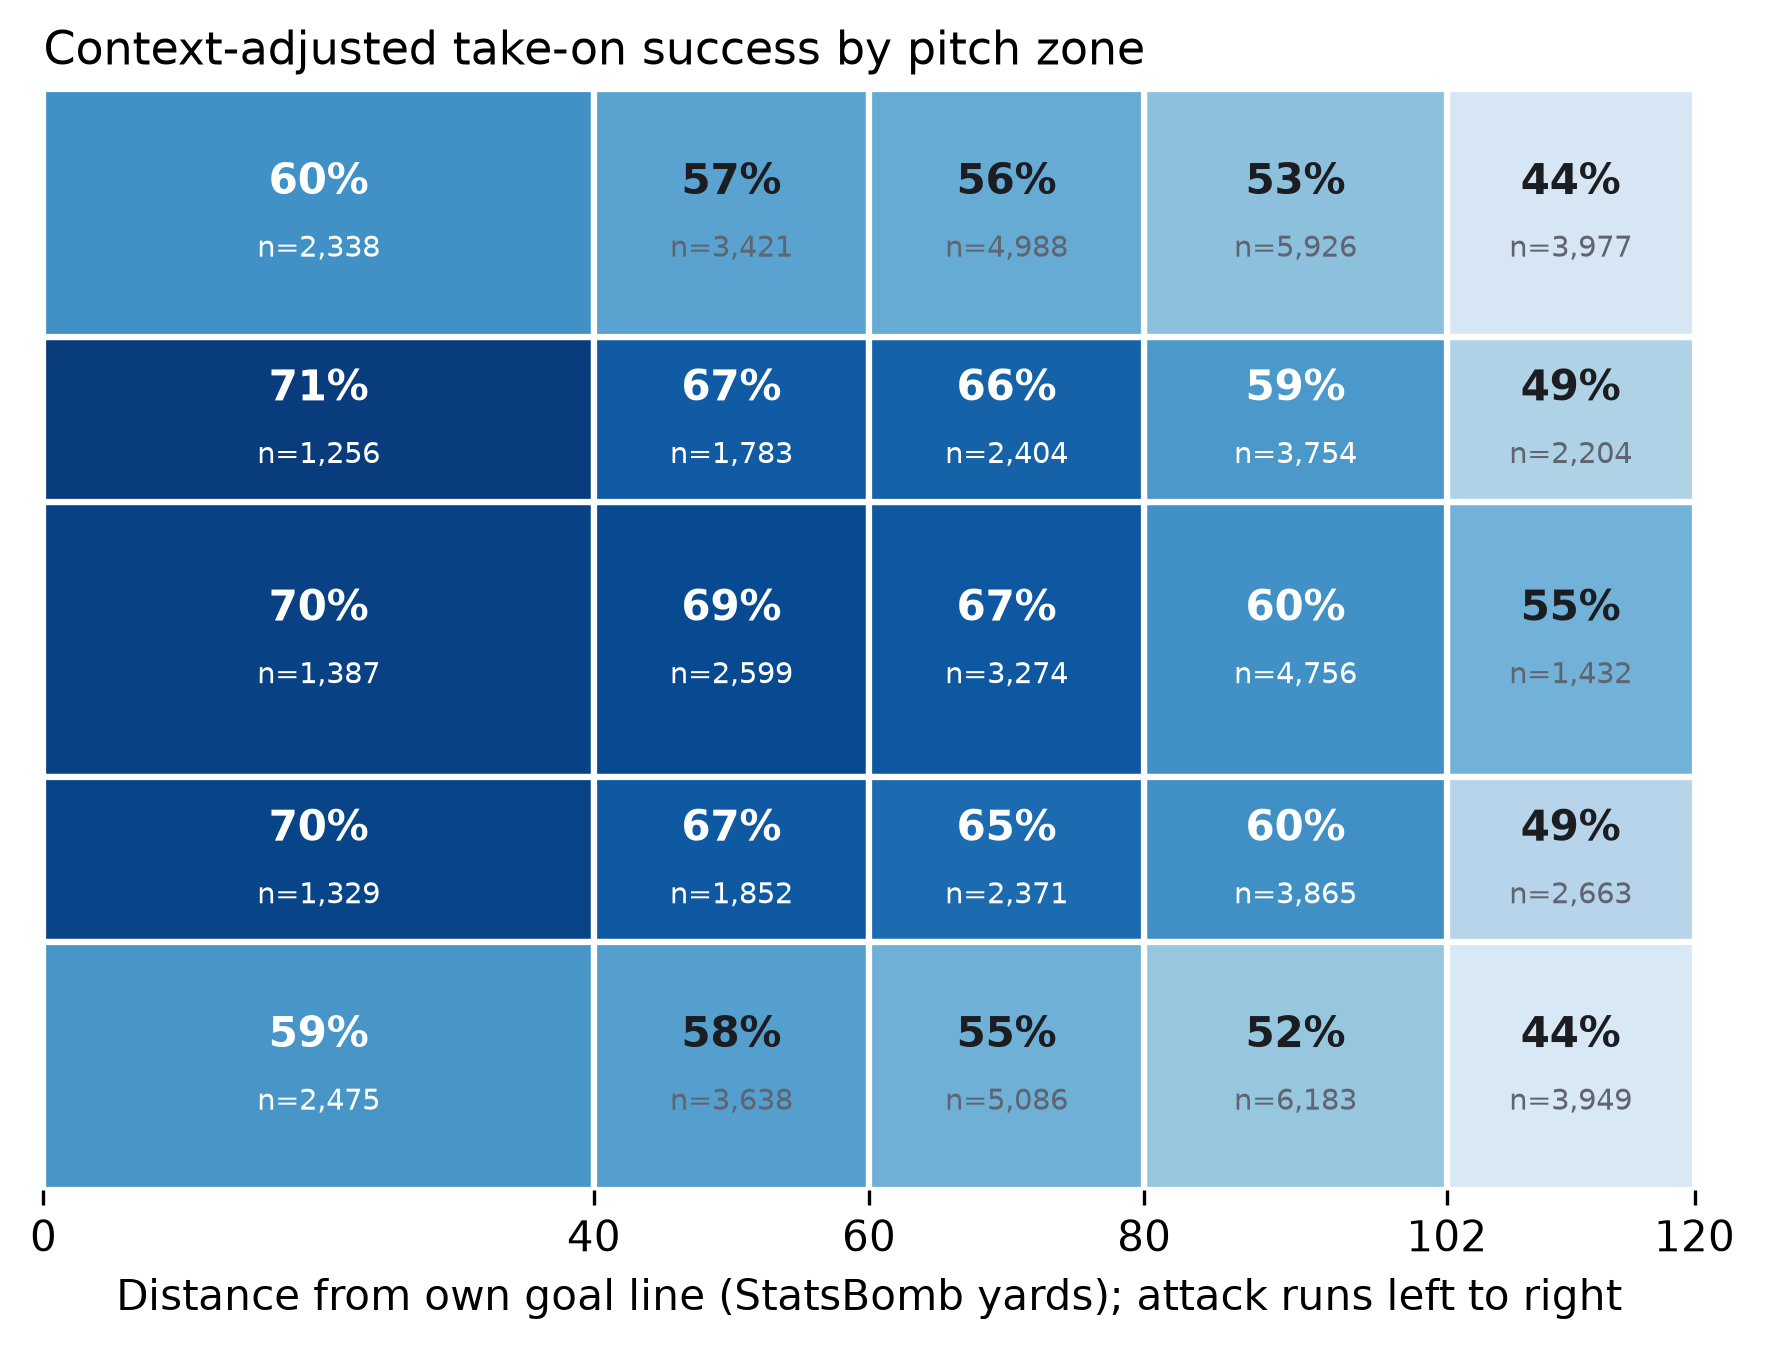

In [2]:
P.fig_context(R);

**Phase of play and score state.** Counter-attacks raise adjusted success to 68.5%, against 59.1% in regular play and 54.9% in other phases (mostly restarts and their second phase), a gain of about 9 points from attacking a defence before it is set. Score state matters little: 57.0% when trailing, 56.9% level and 58.3% leading.

**What completion is worth.** Across all take-ons, a completed one is followed by 0.028 xG later in the same possession, against 0.005 after a failure. shows where that gap comes from. In the final third, a completed central take-on is followed by 0.082 xG and a completed wide one by 0.024: the central take-on is both more likely to succeed (59% against 48% observed) and worth about three times as much. In the central zone of the penalty area a completed take-on is followed by 0.20 xG, against 0.025 after a failure. In the team’s own third, completion is followed by almost nothing in shot value (0.008–0.011 xG), so there its value lies in keeping the ball, not in creating chances.

| Third     | Lane       | Attempts | Success | xG after completed | xG after failed |   Gap |
|:---------|:---------|--------:|-------:|---------------:|-------------:|------:|
| Final     | Central    |    6,211 |   59.4% |              0.082 |           0.014 | 0.068 |
| Final     | Half-space |   12,524 |   55.5% |              0.050 |           0.007 | 0.043 |
| Final     | Wide       |   20,101 |   47.9% |              0.024 |           0.003 | 0.021 |
| Middle    | Central    |    5,860 |   69.0% |              0.022 |           0.005 | 0.017 |
| Middle    | Half-space |    8,390 |   66.6% |              0.019 |           0.003 | 0.016 |
| Middle    | Wide       |   17,101 |   56.4% |              0.016 |           0.002 | 0.013 |
| Defensive | Central    |    1,377 |   71.2% |              0.008 |           0.004 | 0.005 |
| Defensive | Half-space |    2,567 |   71.2% |              0.011 |           0.002 | 0.009 |
| Defensive | Wide       |    4,779 |   59.7% |              0.010 |           0.001 | 0.008 |

**Is the context model reliable on unseen matches?** Out-of-fold discrimination is almost identical to in-sample (AUC 0.601 against 0.604), the Brier score is 0.237 against 0.245 for a constant prediction, and observed completion is within 1.2 points of the prediction in every decile (@fig-uncertainty, left).

### RQ2: How large is skill, how many attempts reveal it, and does the rating predict?

Once context is removed, the true between-player standard deviation of take-on success is $\hat\tau=5.8$ percentage points. That is real but small next to binomial noise. By @eq-rel, a rating needs 74 attempts to have reliability 0.5 (half signal, half noise), 172 for 0.7 and 294 for 0.8 (@fig-reliability). The empirical split-half check agrees: for benchmark players with at least 15 attempts in each half of the season, the correlation between halves is 0.25, a full-season reliability of 0.40.

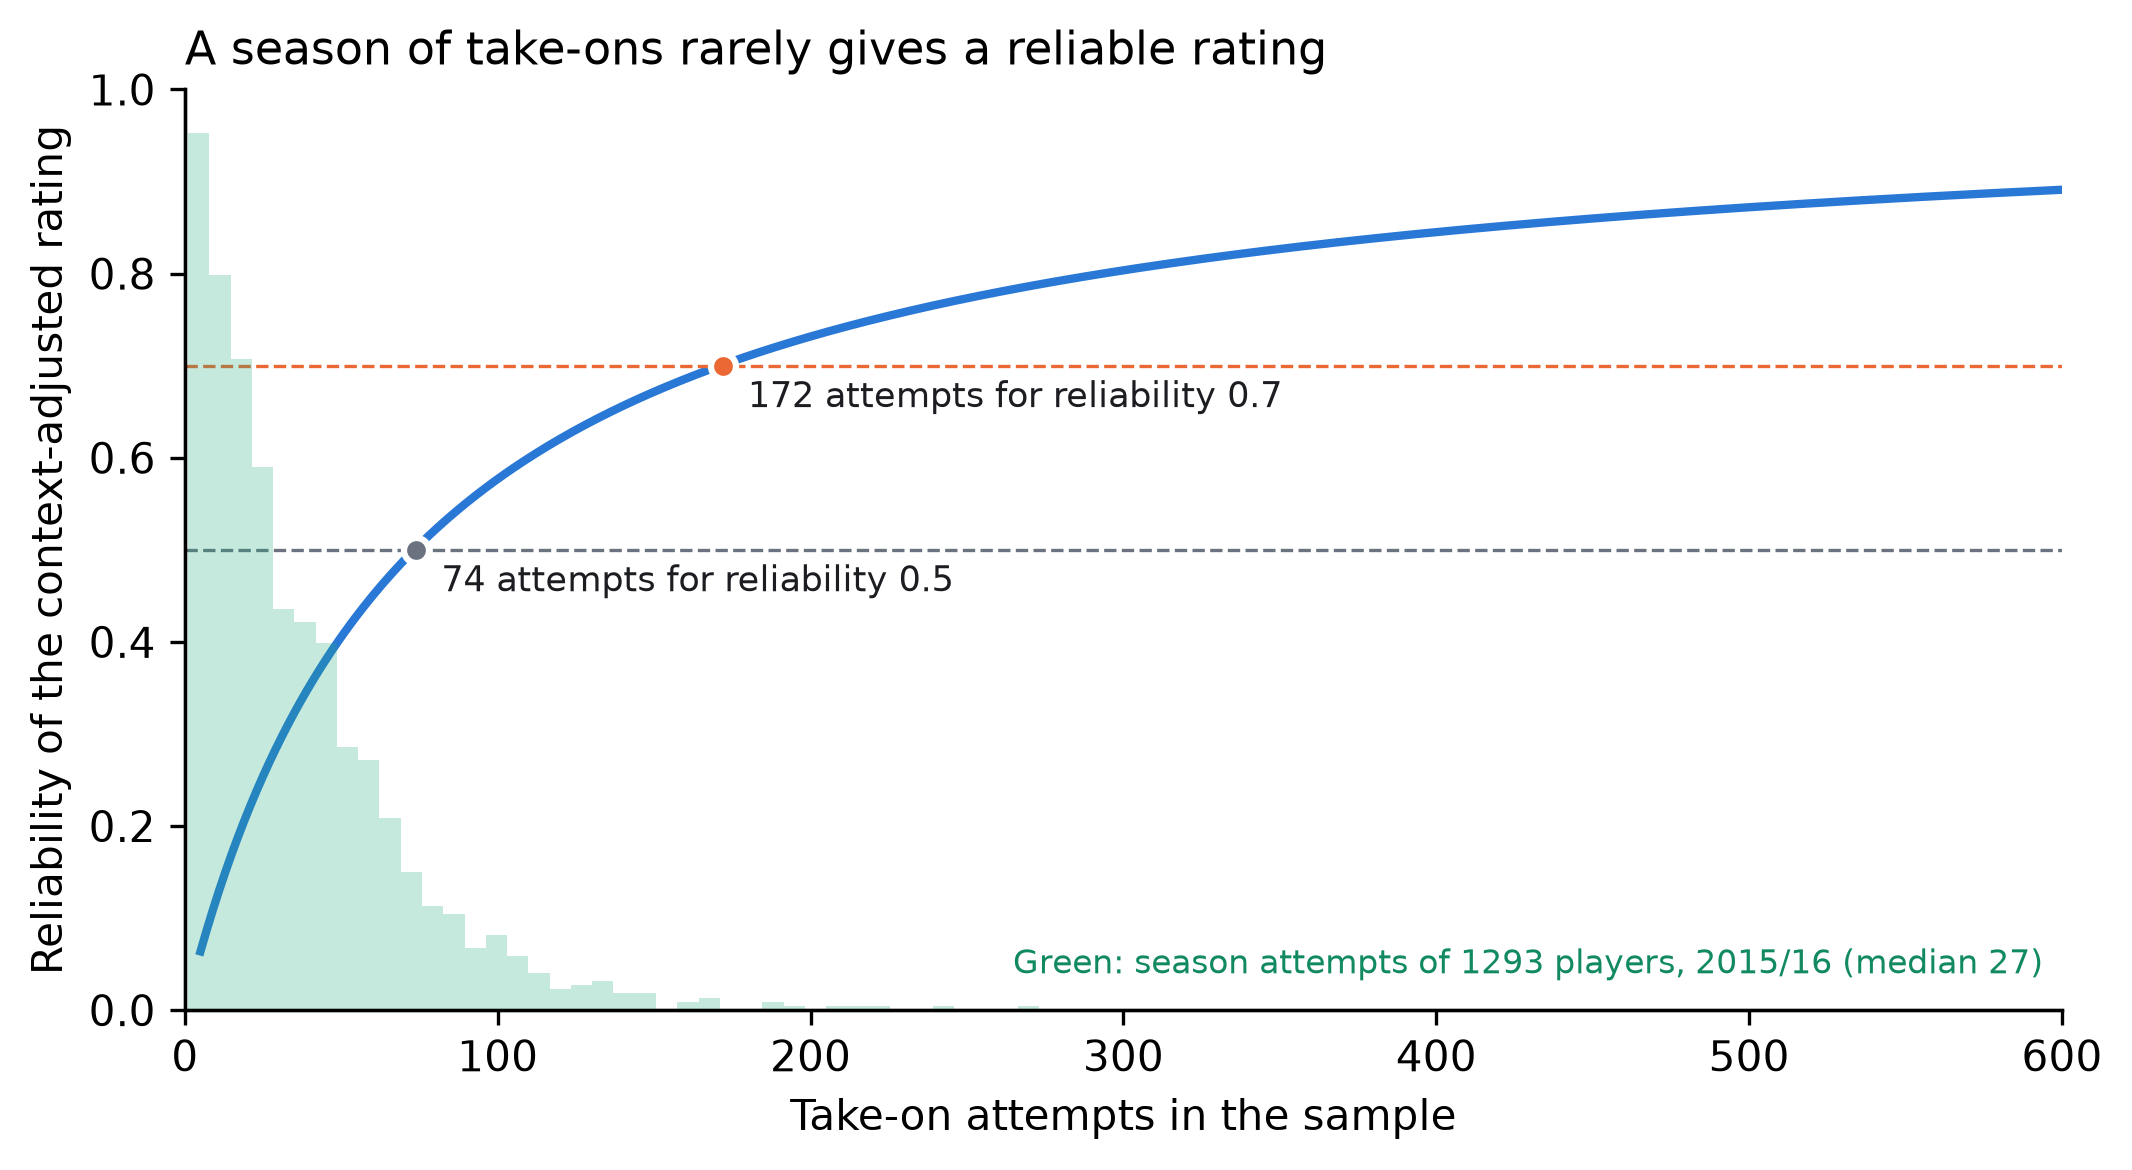

In [3]:
P.fig_reliability(R);

Few players get there in a season. The median benchmark player attempted 27 take-ons in 2015/16, for a reliability of about 0.27. Only 11.5% of players reached 0.5 and 0.6% reached 0.7. At the median rate of 1.28 attempts per 90, a player needs about 134 full matches, more than three seasons, to reach 0.7; a specialist dribbler attempting four per 90 needs about 43. Raw completion rates are noisier still, because they also carry the context effects of @sec-context.

Volume and adjusted success are essentially unrelated across players (Spearman $\rho=-0.09$), so the players who attempt most are not the most efficient, and volume cannot stand in for skill.

**Which rating predicts the rest of the season?** @fig-validity scores five first-half predictions on 19,549 second-half take-ons by 803 players. A player’s raw completion rate is the worst predictor, worse even than giving every player the league average (log loss 0.704 against 0.688): it chases noise and ignores where the player dribbles. Adding the unshrunk context-adjusted rating to the context model also hurts (0.697 against 0.677 for the context model alone). Only the shrunk rating improves on the context model (0.6755 against 0.6769; 95% interval of the gain 0.0001–0.0029), and it beats the raw rate by a wide margin (gain 0.023–0.034). At player level, predicting each player’s second-half success above expectation from his unshrunk first-half value gives a weighted mean squared error 54% larger than predicting zero for everyone, while the shrunk value reduces it by 6%. The gain from skill is small, as @fig-reliability implies, but it is real only once the rating is adjusted for context and shrunk.

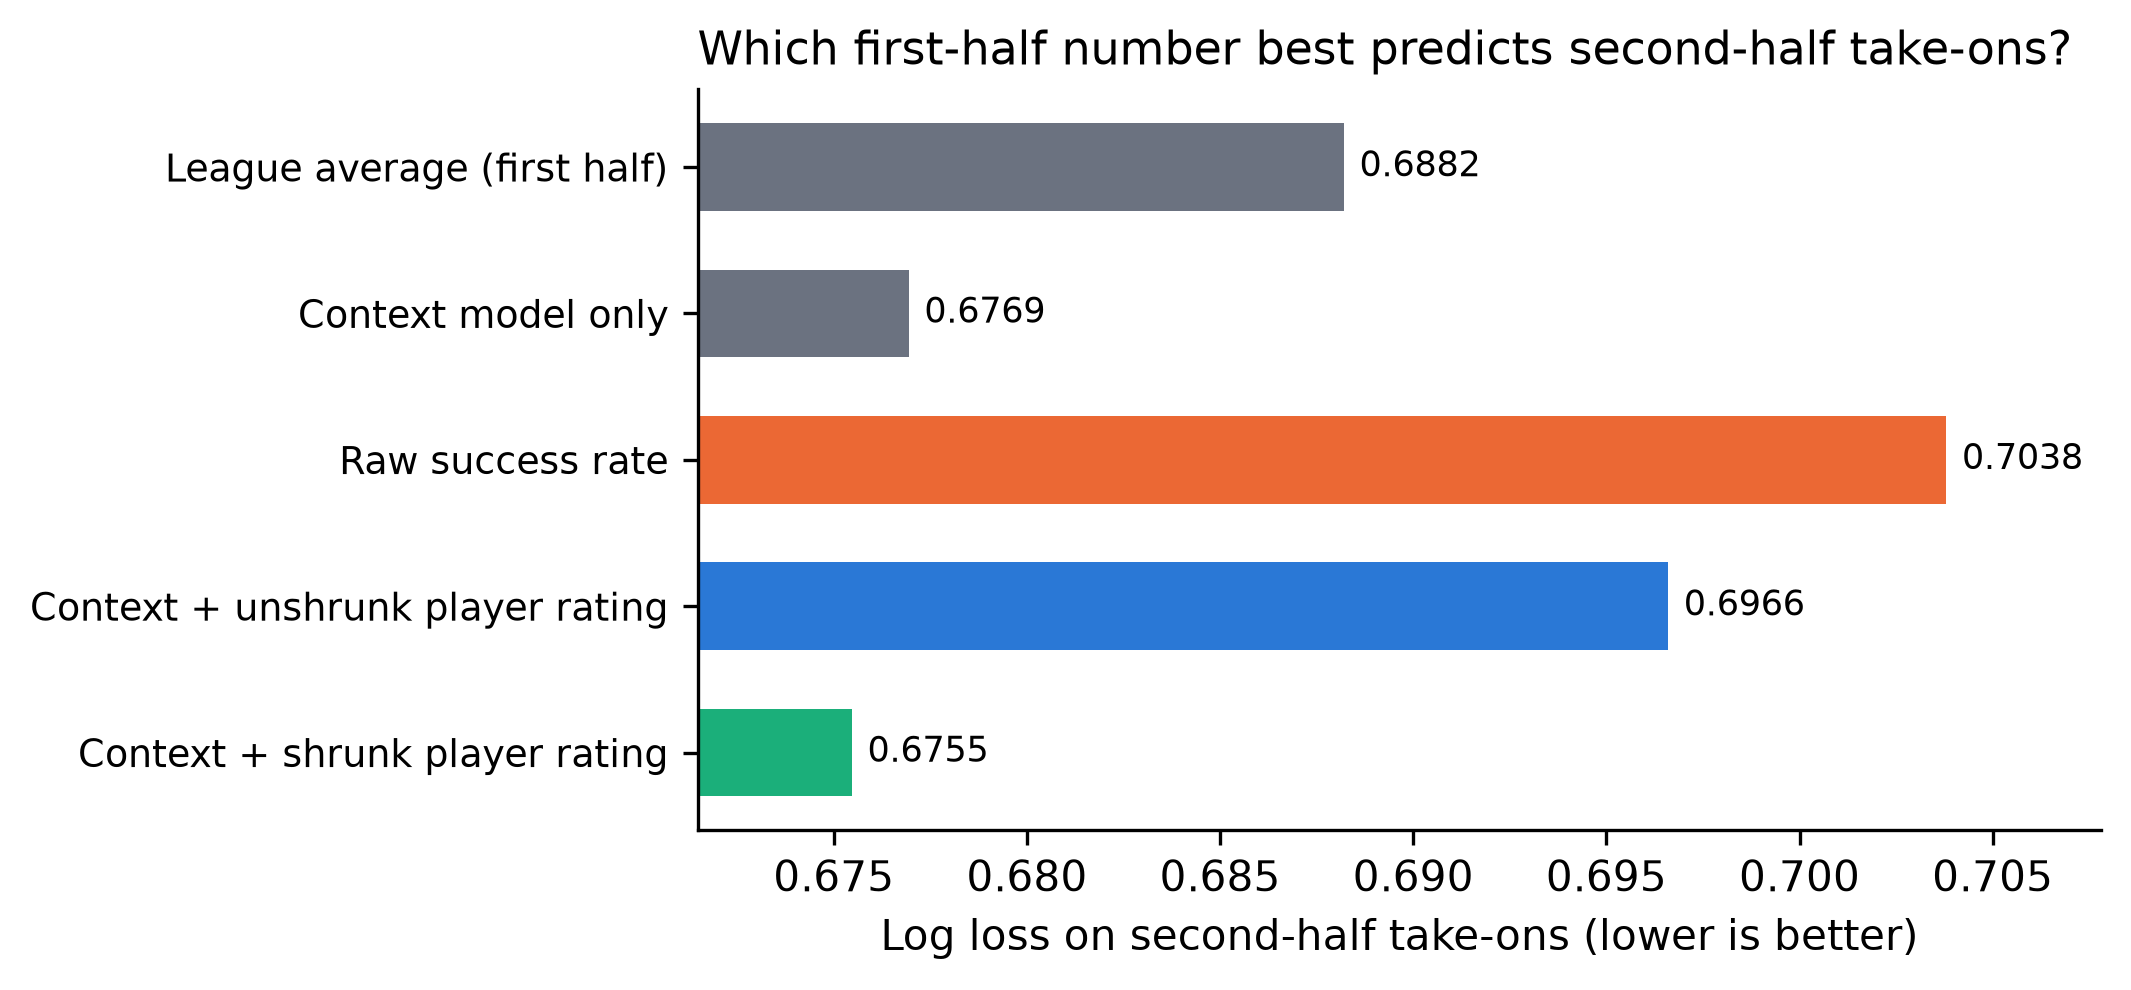

In [4]:
P.fig_validity(R);

### RQ3: When is a take-on worth more than a pass?

@fig-breakeven and @tbl-breakeven give the break-even success rate of @eq-breakeven for each area. Only in the centre of the penalty area does the average take-on clearly beat a pass: there a completed take-on is followed by 0.21 net xG, so it pays off at a success rate of 28% (90% interval 22–34%), and the average take-on, at 53%, adds about 4.7 xG per 100 attempts. Everywhere else the break-even rate is at or above the average success rate. The gap is small in the central channel of the middle and final thirds (2–3 points) and on the wings of a team’s own third, so better-than-average dribblers gain there. It is large on the wings of the final third and the box, where a take-on needs 83–84% success to match a pass (in practice a cross or cut-back) and the average is 42–50%.

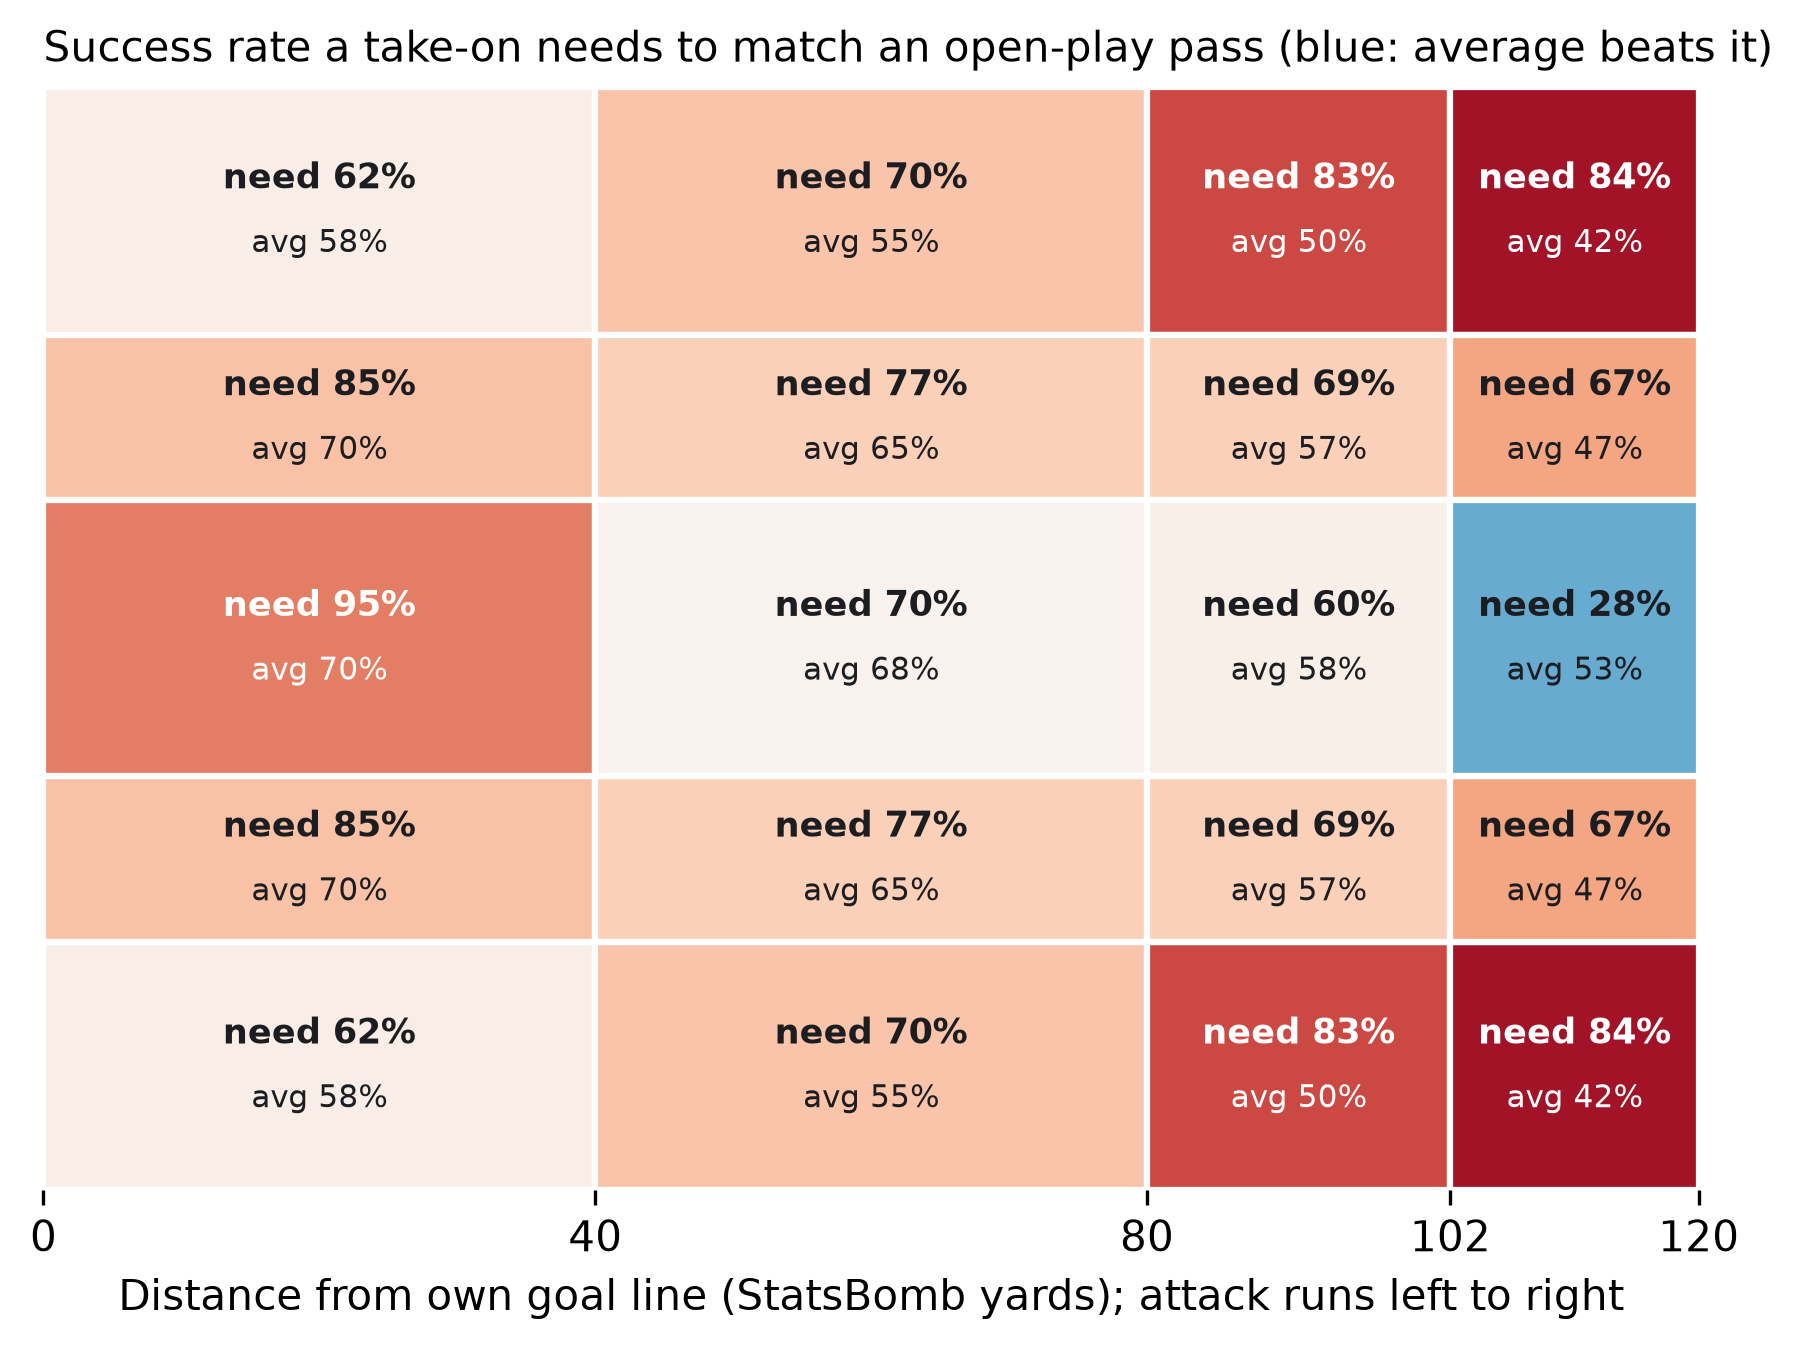

In [5]:
P.fig_breakeven(R);

|  |  |  | Net value per 100 |  |  |  | Worth it for |  |
|:----------|:-------|------:|-----------:|-----:|----:|----------:|:-------:|:-----:|
| 4-6(lr)8-9 Area | Lane | Success | Completed | Failed | Pass | Needed (90% CI) | Median | Top 10% |
| Box | Central | 52.8% | 21.0 | 2.3 | 7.5 | 28% (22–34) | yes | yes |
| Box | Half-space | 47.4% | 6.9 | 0.1 | 4.6 | 67% (61–75) | no | no |
| Box | Wide | 42.0% | 2.4 | $-0.1$ | 2.0 | 84% (73–98) | no | no |
| Final | Central | 57.5% | 4.0 | $-0.1$ | 2.4 | 60% (52–70) | no | yes |
| Final | Half-space | 57.1% | 3.0 | 0.0 | 2.1 | 69% (60–79) | no | no |
| Final | Wide | 49.9% | 1.6 | $-0.1$ | 1.3 | 83% (73–95) | no | no |
| Middle | Central | 67.6% | 1.5 | $-0.9$ | 0.8 | 70% (61–81) | no | yes |
| Middle | Half-space | 64.9% | 1.1 | $-0.7$ | 0.7 | 77% (65–89) | no | no |
| Middle | Wide | 55.4% | 1.0 | $-0.5$ | 0.5 | 70% (60–80) | no | no |
| Defensive | Central | 69.8% | 0.2 | $-0.9$ | 0.1 | 95% (74–100) | no | no |
| Defensive | Half-space | 70.2% | 0.3 | $-1.2$ | 0.1 | 85% (65–100) | no | no |
| Defensive | Wide | 58.3% | 0.4 | $-0.7$ | 0.0 | 62% (46–81) | no | yes |

**The cost of losing the ball.** A failed take-on in a team’s own third is followed by 1.03 opponent xG per 100 in the next possession, against 0.59 after a completed one and 0.78 after a pass; in the middle third the figures are 0.82, 0.61 and 0.66. In the final third and the box a failure concedes no more than a pass (0.58 against 0.58; 0.45 against 0.46). Further forward, the cost of a failed take-on is the attack it ends, not the counter-attack it allows.

**Skill changes the map.** Adding a player’s shrunk rating to the area’s average success changes which areas pay. A median dribbler ($-0.8$ points) clears the break-even rate only in the central box; a top-decile dribbler ($+4.2$) also clears it in the central channel of the middle and final thirds and on the wings of his own third; Messi in 2015/16 ($+13.2$) clears it in six of the twelve areas, adding the half-spaces of the middle and final thirds. Wide areas of the final third and the box remain below break-even for every player in the data.

### RQ4: Ranking with uncertainty, illustrated on the most extreme profile

The most extreme take-on profile in the 2015/16 benchmark belongs to Lionel Messi, who attempted 241 take-ons, the third-highest volume, and is the best-known example in public discussion of dribbling. His case shows why the choice of measure and the reporting of uncertainty matter.

| Measure | Messi | Rank | Percentile |
|:----------------------------------------|-----------:|---------:|----------:|
| Completed take-ons per 90 | 5.74 | 1 / 1,355 | 99.9 |
| Take-ons attempted per 90 | 7.73 | 3 / 1,355 | 99.8 |
| Raw completion rate | 74.3% | – | 77.9 |
| Success above expectation, raw | $+17.3$ pts | – | – |
| Success above expectation, shrunk | $+13.2$ pts | 1 / 604 | – |
| Extra completions per 90 (rate $\times$ volume) | 1.02 | 1 / 604 | – |
| xG later in possession after his take-ons, per 90 | 0.165 | 8 / 1,355 | 99.4 |

**Raw rate understates him; adjusted rate is uncertain; extra completions are clear.** His raw completion rate (74.3%) sits only at the 78th percentile: about a fifth of players had a higher rate, mostly on far fewer attempts. His situations were barely easier than average (expected completion 56.9% against 55.6% for all 2015/16 attempts), even though 54% of his attempts started in the central 28 yards of the pitch’s width, against 24% for the pool. He completed 179 take-ons against 137 expected, $+17.3$ points, or $+13.2$ after shrinkage, the highest of 604 players. With 241 attempts his rating has reliability 0.77 (@eq-rel), unusually high for one season. Even so, his posterior probability of being truly first on the adjusted rate is only 0.15 (match bootstrap: 0.17), of the top three 0.37, and of the top ten 0.72, with a 90% rank interval of 1–32: several low-volume players could plausibly be better. On extra completions per 90 he is far clearer: 1.02, against 0.57 for the next player, with a posterior probability of 0.87 of ranking first and 0.98 of the top three (@fig-uncertainty, right). Volume makes the estimate precise and multiplies the advantage.

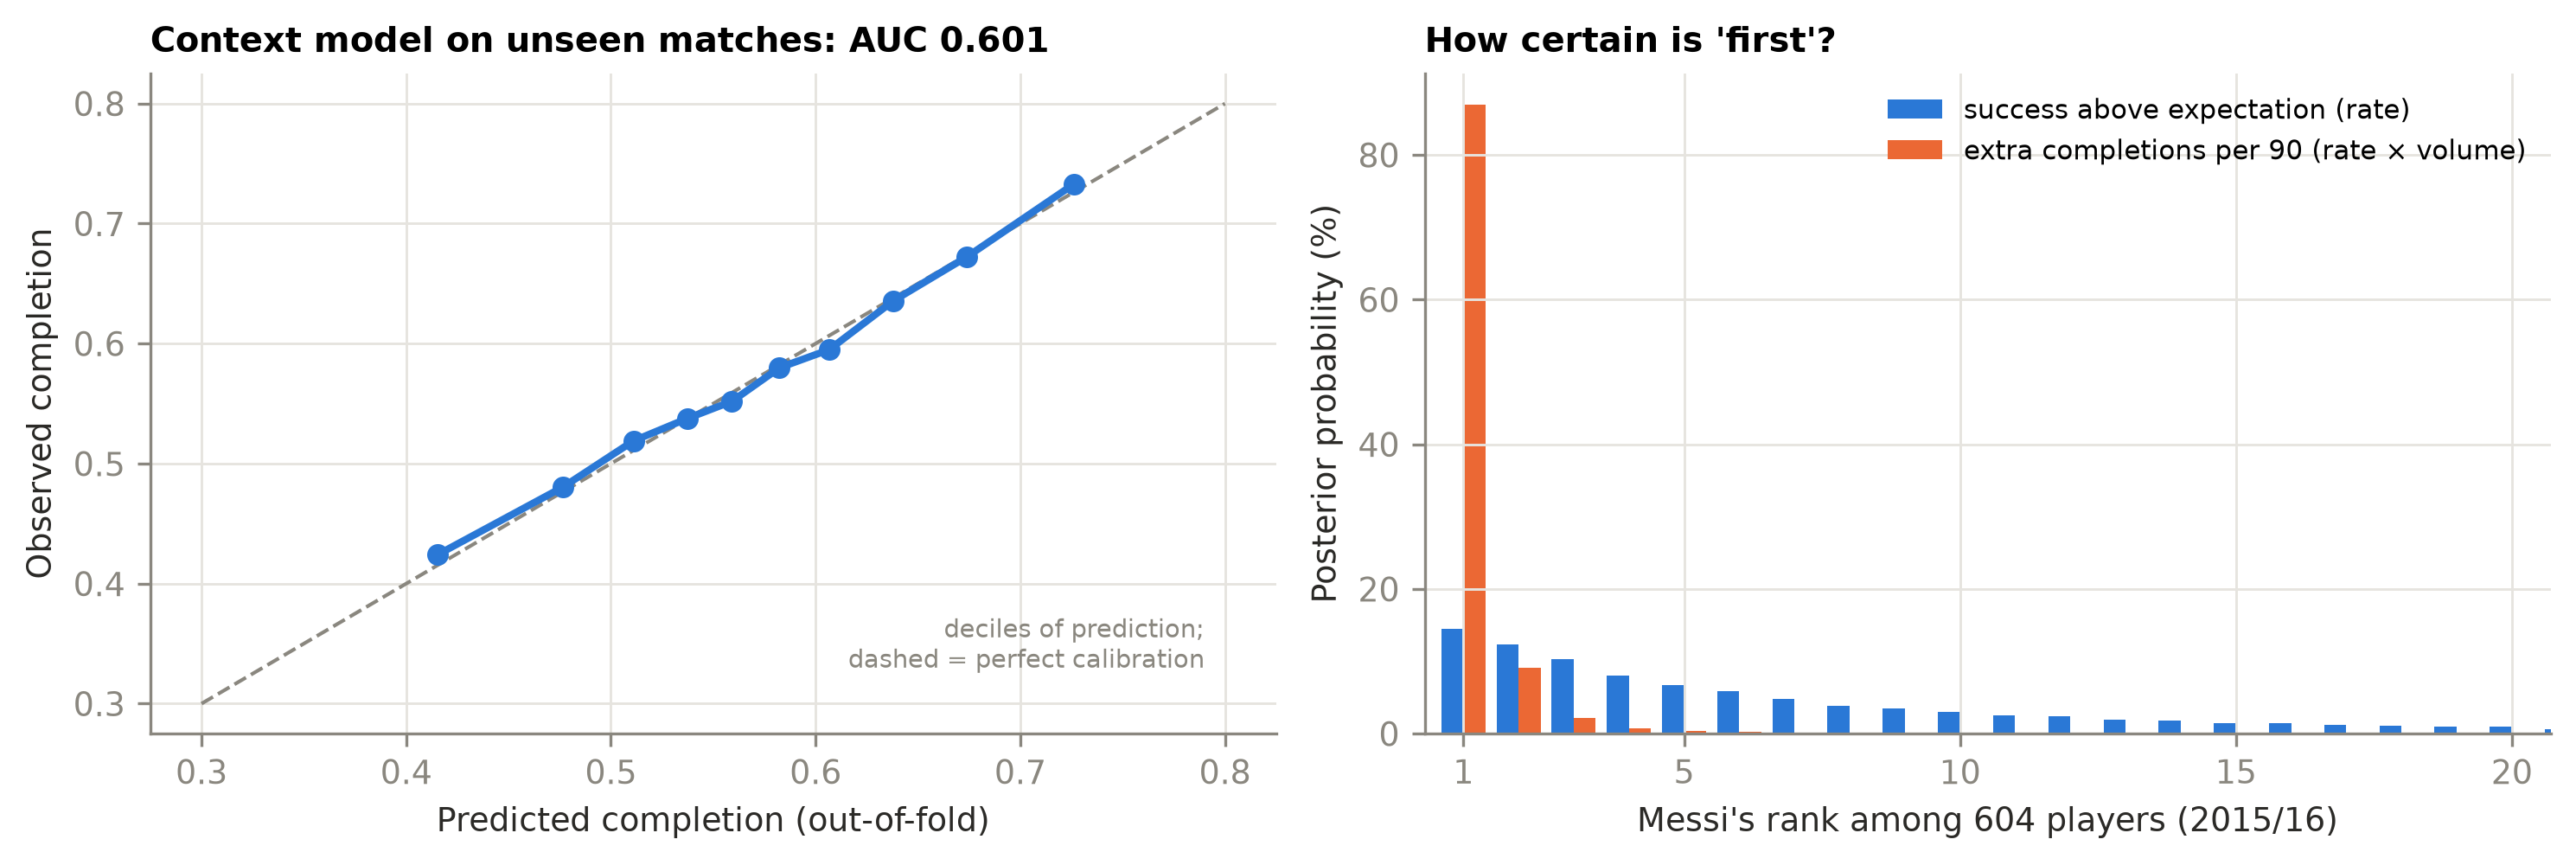

In [6]:
P.fig_uncertainty(R);

The point estimates are stable across seven alternative specifications, and over a career a single season varies by several points even for this player (Appendix B).

## Replication and extension: Studies 2–6

Study 1 rests on one complete season of men’s club football and on event context only. This section asks whether its main answers survive five tests: a different population (women’s football, Study 2), competitions the context model never saw (Study 3), richer context from freeze frames (Study 4), a second data provider (Study 5), and a model that separates the attacker from the defender he faced (Study 6). It ends with a Bayesian version of the dribble-or-pass guide for individual players. Every analysis uses the same code and definitions as Study 1. This section summarises the results; full details are in Appendix A.

| Study | Competitions | Matches | Take-ons |
|:-----|:-----------------------------------------------------------|---:|---:|
| 2\. Women | FA WSL 2018/19, 2019/20, 2020/21, 2023/24 (full except 2019/20, curtailed); NWSL 2018, 2023 (full); Liga F, Frauen-Bundesliga, Serie A Women 2023/24 (full); Women’s World Cup 2019, 2023$^\ast$; Women’s Euro 2022$^\ast$, 2025$^\ast$ | 1,310 | 43,827 |
| 3\. Men, new | FIFA World Cup 2018, 2022$^\ast$; UEFA Euro 2020$^\ast$, 2024$^\ast$; Copa América 2024; Africa Cup of Nations 2023; Indian Super League 2021/22 (full); Bundesliga 2023/24$^\ast$ (one club) | 463 | 13,377 |
| 4\. 360 frames | All matches marked $\ast$ with a usable frame (one Women’s Euro 2022 file is corrupt in the release) | 414 | 11,065 |
| 5\. Wyscout | Premier League, La Liga, Serie A, Bundesliga, Ligue 1 2017/18 (all full); FIFA World Cup 2018; UEFA Euro 2016 \[@pappalardo2019data\] | 1,941 | 52,727 |

### What replicates

@tbl-replicate puts the main quantities side by side. Across two providers, men’s and women’s football, and leagues and tournaments, the following hold: the context effects, the value of completion, a skill spread of about 6 points that needs well over 100 attempts to measure, the failure of the raw rate as a predictor, the small but real out-of-sample gain of the shrunk rating, and the central box as the place where a take-on pays. What does not transfer is the overall level of success, which differs by competition and provider, and the verdict on wide take-ons, which depends on the provider.

|  | StatsBomb |  |  | Wyscout |
|:---------------------------------------|:------:|:------:|:------:|:-------:|
| 2-4(lr)5-5 | 1: men, clubs | 2: women | 3: men, new | 5: men, 2017/18 |
| Matches / take-ons | 2,135 / 78,910 | 1,310 / 43,827 | 463 / 13,377 | 1,941 / 52,727 |
| Overall completion | 57.3% | 55.4% | 54.3% | 60.1% |
| xG after completed / failed | 0.028 / 0.005 | 0.028 / 0.005 | 0.028 / 0.005 | 0.028 / 0.003 |
| Context model AUC (cross-validated) | 0.60 | 0.59 | 0.59 | 0.61 |
| Skill spread $\hat\tau$ (points) | 5.8 | 5.8 | 3.5–4.2 | 6.4 (5.7) |
| Attacker SD in @eq-glmm (points) | 5.7 | – | – | 6.0 |
| Log loss: league average / raw rate | 0.688 / 0.704 | 0.691 / 0.702 | 0.691 / 0.716 | 0.677 / 0.686 |
| Log loss: context / shrunk rating | 0.677 / 0.676 | 0.678 / 0.675 | 0.686 / 0.686 | 0.660 / 0.657 |
| Central box: break-even / average | 28% / 53% | 29% / 60% | 42% / 55% | 31% / 50% |
| Final-third wings: break-even / average | 83% / 50% | 93% / 51% | 90% / 49% | 53% / 55% |
| Box wings: break-even / average | 84% / 42% | 79% / 44% | 76% / 43% | 43% / 43% |

### Prediction across datasets

The test that matters for recruitment, whether a first-period rating predicts a later period, repeats in every dataset with enough players (@fig-replication). The raw completion rate always predicts worse than the league average, and the shrunk rating always does best; in the WSL, where three consecutive seasons are available, the shrunk rating also predicts the next season better than the raw rate.

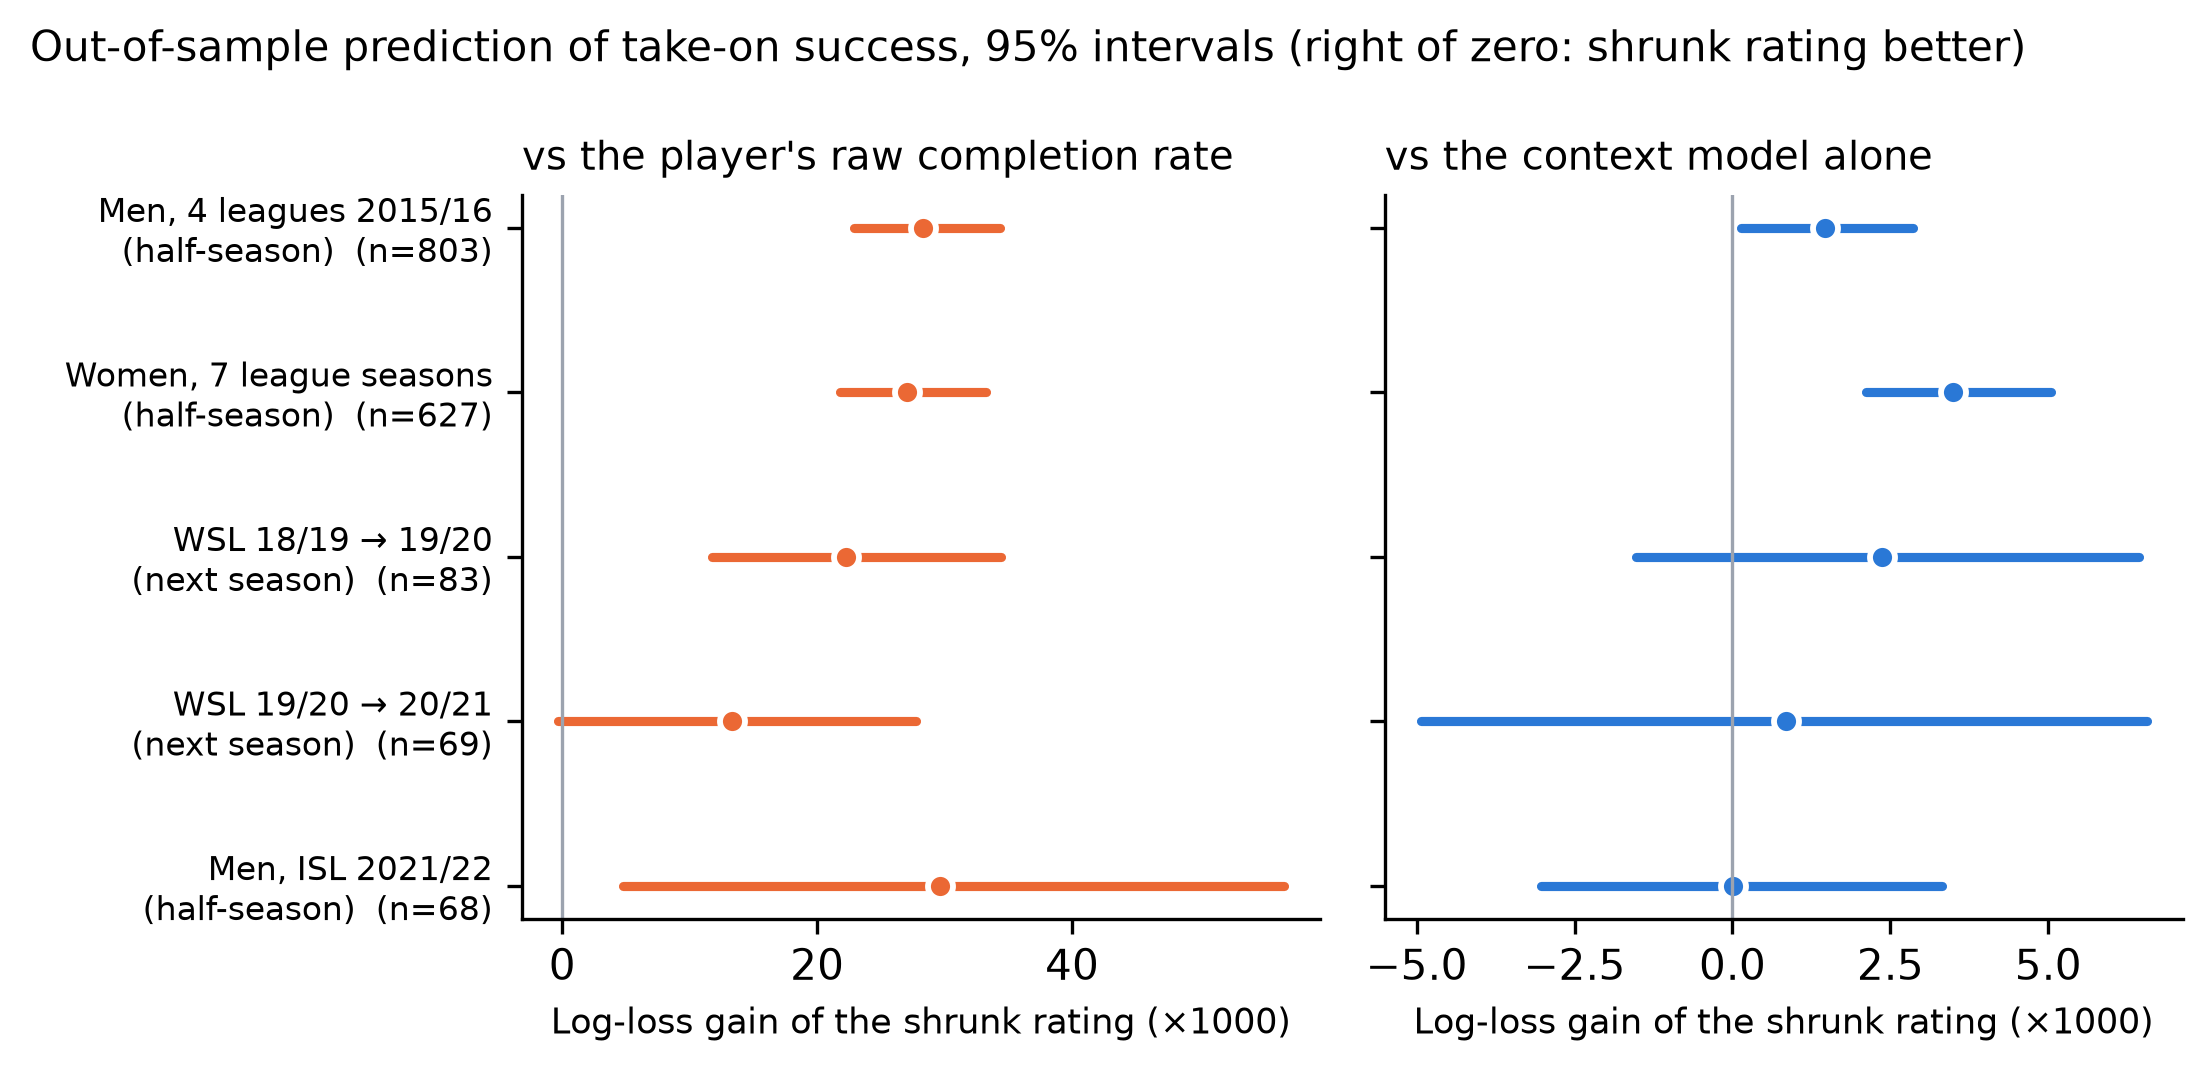

In [7]:
P.fig_replication(R);

### What the extensions add

- **Defenders and teammates (Study 4, 360 freeze frames).** Distance to the nearest opponent moves adjusted success from 47% (within a yard) to 72% (beyond three yards), and defender features raise the cross-validated AUC from 0.58 to 0.63; yet player ratings with and without them correlate at 0.97. With a forward teammate open, a take-on outside the box needs 92–96% success to beat a pass; with none open the bar falls to 64–73%, which confirms that the break-even rates of @tbl-breakeven are conservative for the take-on (Appendix A.3).
- **A data trap.** In the open release, 39.5% of take-on freeze frames, almost exactly the failed ones, are stored mirrored. Used as released they leak the outcome (a spurious AUC of 0.80); the released code re-orients them (Appendix A.3).
- **A second provider (Study 5, Wyscout 2017/18).** The skill spread (6.4 points), the failure of the raw rate and the central-box result replicate; the verdict on wide take-ons does not. On the 61 World Cup 2018 matches coded by both providers, agreement on a player’s attempts per match is only moderate (Lin’s concordance 0.51; 0.75 for tournament totals). Ratings of the same 130 players two seasons and two providers apart correlate at 0.23, or 0.48 after correcting for unreliability (Appendix A.4).
- **Attacker or defender? (Study 6).** In the crossed mixed model the individual defender varies more (7.2–9.6 points) than the attacker (5.7–6.0), but attacker effects with and without defenders correlate at 0.99 or more, and they agree with the two-stage ratings (Appendix A.5).
- **Bayesian decisions.** Posterior probabilities that a take-on beats a pass for each player and area show that where a player chooses to dribble explains about two-thirds of the variation in decision quality (Appendix A.6).

## Implications for practice

**For scouts and recruitment analysts.** - **Do not use raw completion rates.** Pitch zone alone moves expected success by up to 27 points, so a winger who dribbles in the box and a midfielder who dribbles in his own half are not comparable on raw rate. Out of sample, a player’s raw rate predicts his next half-season worse than the league average does (@fig-validity). Use success above context expectation, shrunk; the released table (Reproducibility section) gives it for 604 players with 90% intervals and a reliability for each.

- **Treat one season as weak evidence.** With a between-player spread of 5.8 points, a rating needs about 170 attempts to be mostly signal. For most players that is three or more seasons; pool seasons and competitions, and shrink (@eq-oe).

- **Rank on extra completions per 90, with probabilities.** It combines efficiency with volume, is far more precise than the rate, and identifies the players who actually produce more successful take-ons. Report the probability of being in the top group, not a bare rank.

- **The rules hold in women’s football.** The skill spread, the reliability curve and the failure of the raw rate are the same in the women’s game (Appendix A.1), so the same thresholds apply to women’s scouting.

- **Adjust for the competition.** Take-ons are about two points harder at international tournaments than the league model expects (Appendix A.2); compare players within a competition or include a competition term.

- **Scout defenders one-against-one, too.** Individual defenders differ more than attackers in how often they are beaten (@fig-attdef); defender effects from @eq-glmm are a natural event-data measure of one-against-one defending.

- **Judge decisions, not just success.** The decision score of Appendix A.6 separates a player’s skill from where he chooses to dribble; most of its variation comes from the choice, which is coachable.

- **Never mix providers.** On the same World Cup matches the two providers agree only moderately on a player’s attempts (Appendix A.4).

**For coaches.** - **A dribble-or-pass guide.** gives, for each area, the success rate a take-on needs to beat a pass. It can be used directly in video review and player meetings: in the central box, take on a defender whenever the chance of beating him is better than about one in three; in the central channel of the middle and final thirds, encourage it for the team’s best dribblers (top decile), not for everyone; on the wings of the final third and the box, the pass or cross is the better option on average even for elite dribblers.

- **Look up before taking on.** With a forward teammate open, a take-on outside the box needs over 90% success to beat the pass; with none open, the bar drops to 64–73% (@fig-360be). A simple coaching cue follows: if a teammate ahead is free, pass; take the defender on when nobody is, and above all in the central box.

- **Create distance first.** Success rises from 47% with the defender within a yard to over 70% beyond three yards (@fig-360). Receiving on the half-turn or with a first touch away from the defender before committing to a take-on is worth practising.

- **Where to encourage take-ons.** In the final third, central and half-space take-ons both succeed more often and are worth more than wide ones (@tbl-value; @tbl-breakeven). Coaching a winger to cut inside before taking on a defender trades a low-value duel on the touchline for a more productive one, provided the player can complete it.

- **When to encourage them.** Take-ons in transition succeed about 9 points more often than in regular play. Encouraging one-against-one duels early in a counter-attack, before the defence is organised, raises the odds.

- **Where not to risk them.** In the defensive third, completed take-ons add almost no shot value, and a failure there gives the opponent about a third more xG in the next possession than a pass does; a central take-on in a team’s own third needs about 95% success to pay. Further forward the risk is the lost attack, not a counter.

- **Evaluating training effects.** Because season ratings are noisy, a change of a few points after a training intervention cannot be distinguished from chance unless it rests on well over 100 attempts.

**For analysts building metrics.** The pipeline of @sec-method is general: any binary on-ball action with a context model (passes into the box, crosses, shots) can be rated above expectation, shrunk, given a reliability curve from @eq-rel, tested out of sample as in @sec-valid-method, and compared with its alternative through a break-even rate (@eq-breakeven) before it is used for decisions.

## Limitations

- **Context is coarse.** uses event context only and discriminates modestly (AUC 0.60). Freeze frames (Study 4) add defender positions and raise the AUC to 0.63 while leaving player ratings almost unchanged, but they are snapshots: they omit the attacker’s and defender’s speed and body orientation, which need tracking data \[@fernandez2021\]. Some of what we call skill may still be unmodelled context, so $\tau$ is an upper bound on skill and the attempt counts in @sec-reliability are lower bounds.

- **Value is associational.** Possession xG after a take-on shares credit with every later action and does not show that the take-on caused the chance \[@decroos2019\]. The coaching implications in @sec-practice are hypotheses for controlled study, not proven effects; in particular, the players who attempt central take-ons may differ from those who attempt wide ones.

- **The pass is not a randomised alternative.** Players attempt take-ons when they judge that no good pass is on, so passes from the same area are not exactly the option the dribbler had. This selection probably favours the pass, so the break-even rates in @tbl-breakeven are best read as conservative and as a ranking of areas rather than exact thresholds. Study 4 confirms the direction: when no forward teammate is open, the break-even rate outside the box falls by 20–30 points. Its intervals are wide, and a defender-free teammate in a snapshot is a rough proxy for a real passing option.

- **Prediction gain is small.** The out-of-sample gain of the shrunk rating over the context model alone is small (@fig-validity), as expected from a skill spread of 5.8 points; it is the gain over the raw rate that is large.

- **Coverage.** Only 2015/16 has complete men’s leagues; other men’s seasons cover single clubs, so career series describe players in strong teams. The women’s data have more complete seasons but fewer attempts per player, and only the WSL has consecutive seasons, so the next-season test rests on 69–83 players per pair.

- **Two providers, harmonised by us.** Wyscout’s possessions and expected goals were rebuilt by us (Appendix A.4), and the World Cup comparison shows that the two providers count take-ons differently; results that depend on the exact definition, such as the verdict on wide take-ons, are provider-dependent.

- **Defender identity.** In StatsBomb the defender of a completed and of a failed take-on are identified by different events, which may inflate the defender variance in @eq-glmm; Wyscout’s symmetric pairing gives a smaller but still larger-than-attacker estimate. Both mixed models use the fast `nAGQ = 0` approximation.

- **Provider definitions.** All results are StatsBomb-specific and should not be compared with Opta-based figures.

- **Unmeasured constructs.** Feints, touches per dribble, first-touch direction and scanning are not recorded in event data.

## Conclusion

A take-on completion rate mixes three things: where and when the take-on was attempted, the player’s skill, and chance. On 78,910 open-data take-ons, context moves success by up to 27 points, skill differences are real but small (about 5.8 points), and a single season rarely contains enough attempts to tell them apart from chance: a rating needs about 170 attempts to reach a reliability of 0.7, and the median player attempts 27 a season. Rating players by completions above context expectation, shrunk, and by extra completions per 90 with rank probabilities, gives rankings that hold up on held-out matches and state their own uncertainty; out of sample, the shrunk rating predicts future take-ons best, while the raw completion rate predicts worse than the league average. Counting the opponent’s chances after a turnover, a take-on beats a pass on average only in the centre of the penalty area; better dribblers gain in the central channel, and no player in the data gains on the wings of the final third and the box. These answers replicate in 1,310 women’s matches, where the skill spread is again 5.8 points and the shrunk rating also predicts the next season, and in 463 men’s tournament and league matches the model never saw. Freeze frames add the defenders: distance to the nearest defender moves success by about 25 points, yet player ratings barely change, and when no forward teammate is open the take-on comes much closer to paying. A second provider, Wyscout, reproduces the skill spread, the failure of the raw rate and the central-box result two seasons later, while disagreeing on wide take-ons; and a crossed attacker–defender model shows that the defender a dribbler meets matters more than which dribbler it is, without changing the attacker ratings. Applied to the most extreme profile in the data, the method confirms an exceptional producer of take-ons while showing that claims of being the most efficient dribbler are much weaker than raw rankings suggest. The same framework applies to any binary on-ball action.

## Reproducibility

All data are public: StatsBomb open data (<https://github.com/statsbomb/open-data>, StatsBomb Public Data User Agreement) and the Wyscout release of @pappalardo2019data (CC BY 4.0). Code, derived data, the released ratings and every figure are at <https://github.com/shiroonigami23-ui/dribbling-context-skill-chance>. From the `code/` folder, `bash run_all.sh` downloads the raw data (about 2 GB) and rebuilds every number, table and figure in this paper (Python 3 with pandas, statsmodels and scikit-learn; R with `lme4` for the mixed model), and `python src/check_reproduction.py` compares a fresh run with the committed results; a fresh run on 25 November 2026 matched all 289,371 committed numbers to within 1% (Python and R package versions are in `code/requirements-lock.txt`). The file `results/ratings_2015_16.csv` gives, for the 604 rated players, attempts, raw and expected completions, the raw and shrunk rating with a 90% interval and its reliability; `results/breakeven_third_lane.csv` gives the break-even table, and the corresponding Study 2–4 tables are in the same folder. The 360 re-orientation is in `src/fetch_more.py`.

## Acknowledgements

Code and data repository: <https://github.com/shiroonigami23-ui/dribbling-context-skill-chance>. We thank StatsBomb and Wyscout (Pappalardo et al.) for releasing their data openly. An AI assistant (Anthropic’s Claude) was used to help write analysis code, check references and edit the language; the author designed the study, checked all code and outputs, and takes full responsibility for the content.

## Disclosure statement

The author has no conflicts of interest to declare and received no funding for this work.

## References

## Appendix A: Details of Studies 2–6

### A.1 Study 2: women’s football

The context effects are the same in shape and similar in size. Completion is 55.4% overall and falls with depth (59% in the defensive third, 48% in the box); counter-attacks raise it most (74% against 59% in regular play, observed). A completed take-on is followed by 0.028 xG later in the possession and a failed one by 0.005, the same values as in men’s football to the third decimal. The cross-validated AUC of the context model is 0.59.

**The skill spread is the same.** Among the 384 player-seasons with at least 900 minutes and 30 take-ons in the five women’s leagues, the between-player standard deviation is $\hat\tau=5.8$ points, as in Study 1, so the same attempt counts apply: 74 for reliability 0.5 and 172 for 0.7. The median women’s league player attempted 12 take-ons in a season, and fewer than 2% reached a reliability of 0.5.

**Prediction, including the next season.** In the seven full league seasons, the first-half/second-half test of @sec-valid-method (627 players, 11,197 second-half take-ons) repeats the men’s result: raw completion rate predicts worse than the league average (log loss 0.702 against 0.691), and the shrunk rating predicts best (0.675, against 0.678 for the context model alone; 95% interval of the gain 0.0021–0.0050). The WSL has three consecutive seasons, which allows the test recruitment cares about most: rate a player on one season and predict the next. With the context model and ratings fitted on season $t$ only, the shrunk rating gives the lowest log loss for season $t+1$ in both pairs (2018/19 $\rightarrow$ 2019/20, 83 players: 0.649 against 0.672 for the raw rate; 2019/20 $\rightarrow$ 2020/21, 69 players: 0.670 against 0.684). Its gain over the raw rate is clear in the first pair and borderline in the smaller second; its gain over the context model alone is positive in both but not distinguishable from zero at these sample sizes (@fig-replication in the main text).

**Dribble or pass.** The women’s break-even table has the same headline. In the central box a take-on needs 29% success to match a pass and averages 60%; on the wings of the final third and the box it needs 93% and 79% and averages 51% and 44%. In the middle third the pass is worth relatively more than in men’s football (break-even rates of 98–100%), so the average and the top-decile dribbler clear the break-even rate only in the central box.

### A.2 Study 3: men’s competitions the model never saw

We refit the Study 1 context model without its competition term and score the 13,377 take-ons of Study 3 without refitting. It discriminates almost as well as a model refitted on the new data (AUC 0.582 against 0.586 cross-validated) and ranks attempts in the same order, but it is about two points too optimistic on average (predicted 56.5%, observed 54.3%; calibration slope 0.84, largest decile gap 5.6 points). Take-ons are harder at international tournaments than in a domestic league season (from 47% at the Copa América 2024 to 58% at the World Cups), so a model fitted on league football needs a competition offset before it is applied elsewhere, which is what the competition term in @eq-glm does.

The other results repeat where the sample allows. Completion after a take-on is followed by 0.028 against 0.005 xG. The break-even table again has the central box (needed 42%, average 55%) and the central final third (45% against 60%) as the areas where the average take-on beats a pass (with, narrowly and on few attempts, the half-spaces of the defensive third), and the wings of the final third and the box as the worst (90% and 76% needed, 49% and 43% achieved). In the full Indian Super League season the raw completion rate again predicts the second half worse than the league average (log loss 0.716 against 0.691; 68 players), and the shrunk rating is as good as the context model and better than the raw rate. Tournaments are too short to rate players: the median player in Study 3 attempts three take-ons per competition, and the skill spread estimated from the 182 player-competitions with at least 15 attempts (4.2 points) is less precise than in Studies 1 and 2.

### A.3 Study 4: the defenders and teammates around the ball

StatsBomb 360 data give, for each event, the positions of all players in the broadcast camera’s view. For every take-on and open-play pass in 414 matches (7,408 men’s and 3,657 women’s take-ons; 144,860 passes) we computed the distance from the ball carrier to the nearest opponent, the number of opponents within 3 and 5 yards, the number of opponents goal-side in a 30° cone towards goal, and the number of open teammates (no opponent within 5 yards, within 35 yards of the ball), counting a teammate as *forward* if he or she is at least two yards nearer the opponent’s goal line. Frames in which fewer than three opponents are visible are dropped.

**A data trap.** In the open-data release, 39.5% of take-on frames, almost exactly the failed ones, are stored in the opposite orientation to their event: the ball carrier appears at $(120-x,\,80-y)$. Only 0.002% of pass frames are affected. Used as released, the frames leak the outcome, and a model with defender features reaches an implausible AUC of 0.80 with effects in the wrong direction. We re-orient every frame so that the ball carrier sits at the event location; all results below use the corrected frames, and the correction is in the released code.

**Defender context matters, and it is mostly distance.** Adding the defender features to @eq-glm raises the cross-validated AUC from 0.585 to 0.627 and lowers the Brier score from 0.243 to 0.236 (0.248 for a constant). Distance to the nearest opponent has the largest effect: adjusted success is 47% with an opponent within a yard, 56% at 1–2 yards, 61% at 2–3 yards and 72% beyond 3 yards (@fig-360). More open forward teammates go with higher success (51% with none, 63% with three or more), probably because a spread defence leaves more room for the dribbler.

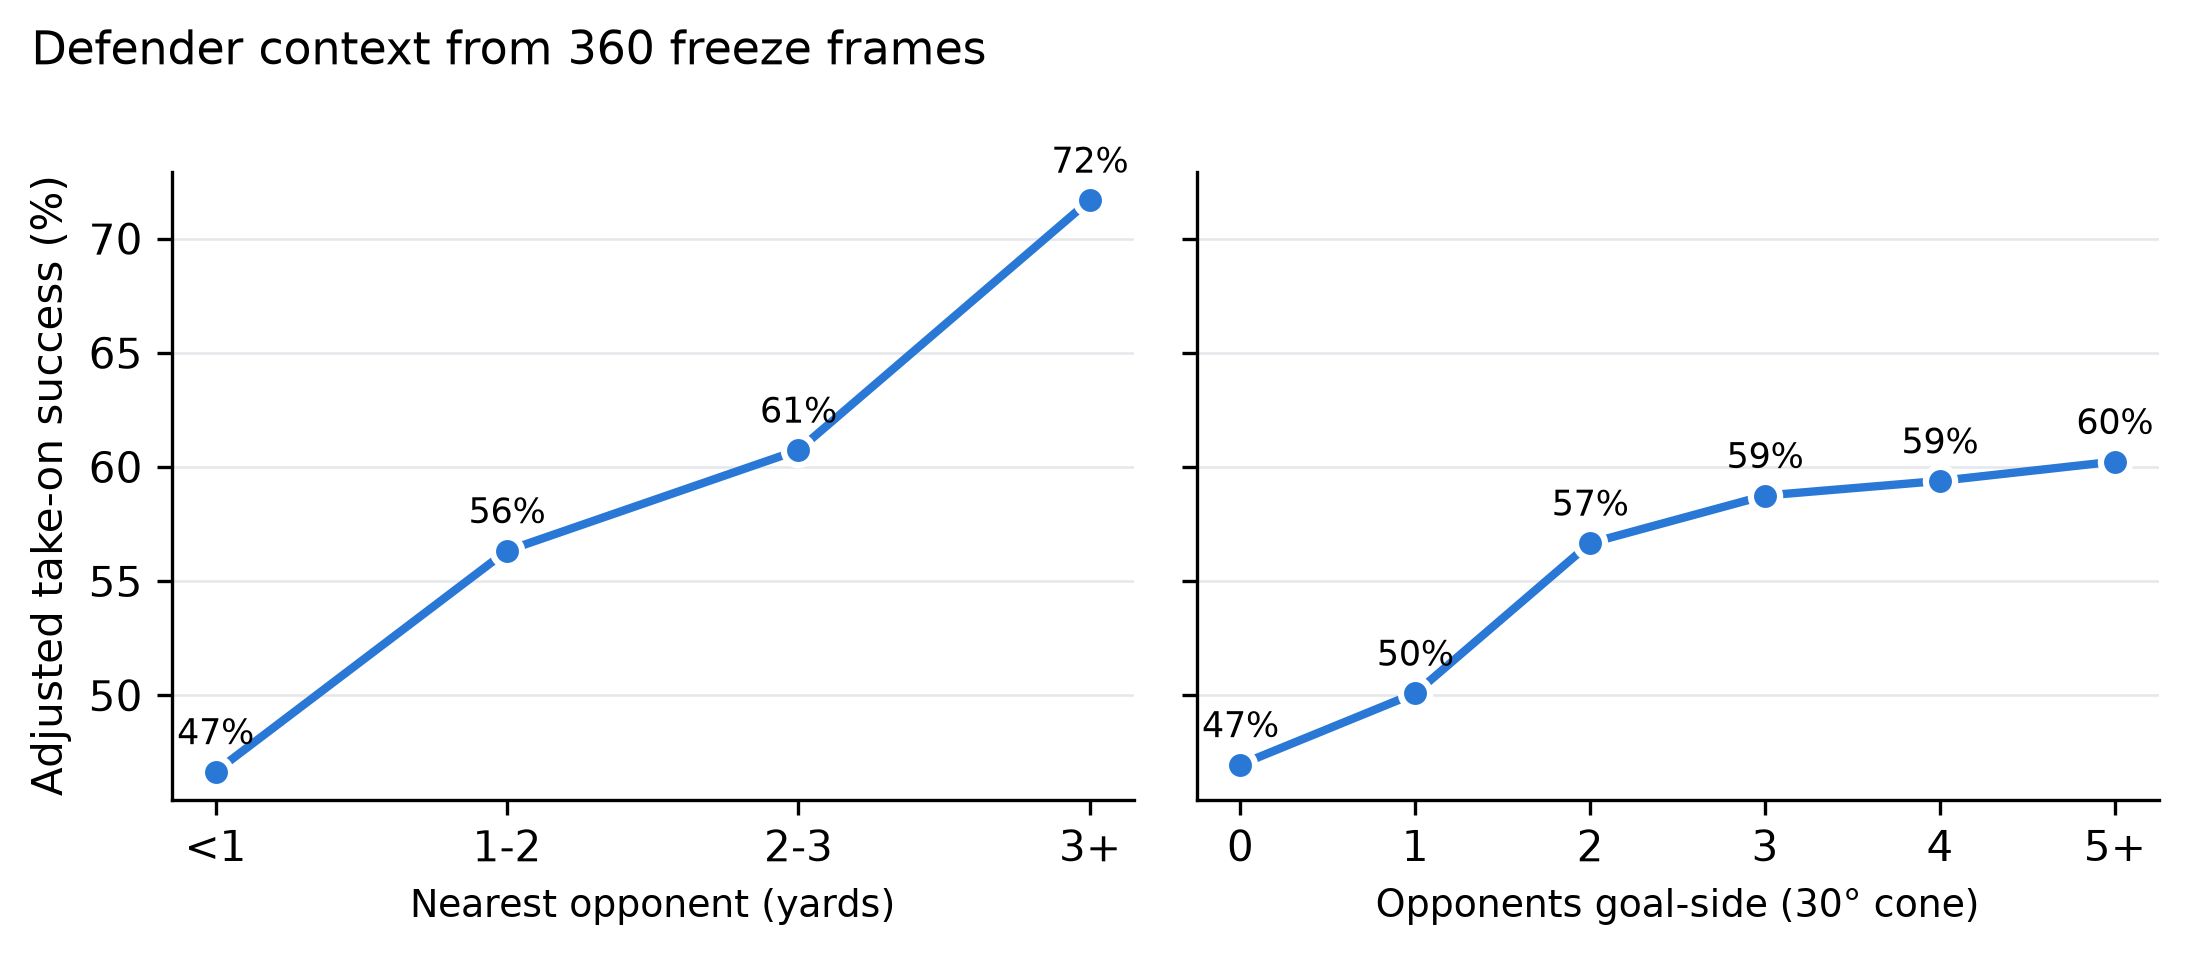

In [8]:
P.fig_360_context(R);

**Ratings barely move.** Study 1 warned that some of what it called skill might be unmodelled context. On the same take-ons, player ratings computed with and without the defender features correlate at 0.97 (147 players with at least 15 attempts; 0.96 and 0.97 at 20 and 30 attempts). The estimate of the skill spread itself is too imprecise in this sample to say whether it shrinks (4.6 points without defender features and 3.8 with them at 15 attempts; 4.5 and 4.7 at 30), but the ordering of players, which is what scouting uses, is almost unchanged.

**When no teammate is open, the take-on comes closer to paying.** The main weakness of the break-even analysis in @sec-decision is that passes from the same area are not the option a dribbler actually had. The freeze frames let us compare like with like: take-ons and passes made when at least one forward teammate was open, and those made when none was (@fig-360be). Outside the box, with a forward teammate open, a take-on needs 92–96% success to match a pass and averages about 61%: the pass is clearly better. With no forward teammate open, the break-even rate falls to 73% (90% interval 58–100%) in a team’s own half and middle third and to 64% (49–83%) in the final third, against an average of about 50%. Players already respond to this: take-ons make up 15% of actions in the final third when no forward teammate is open, against 8% when one is. In the box the break-even rate is about 48% either way, close to the average success of 46–52%.

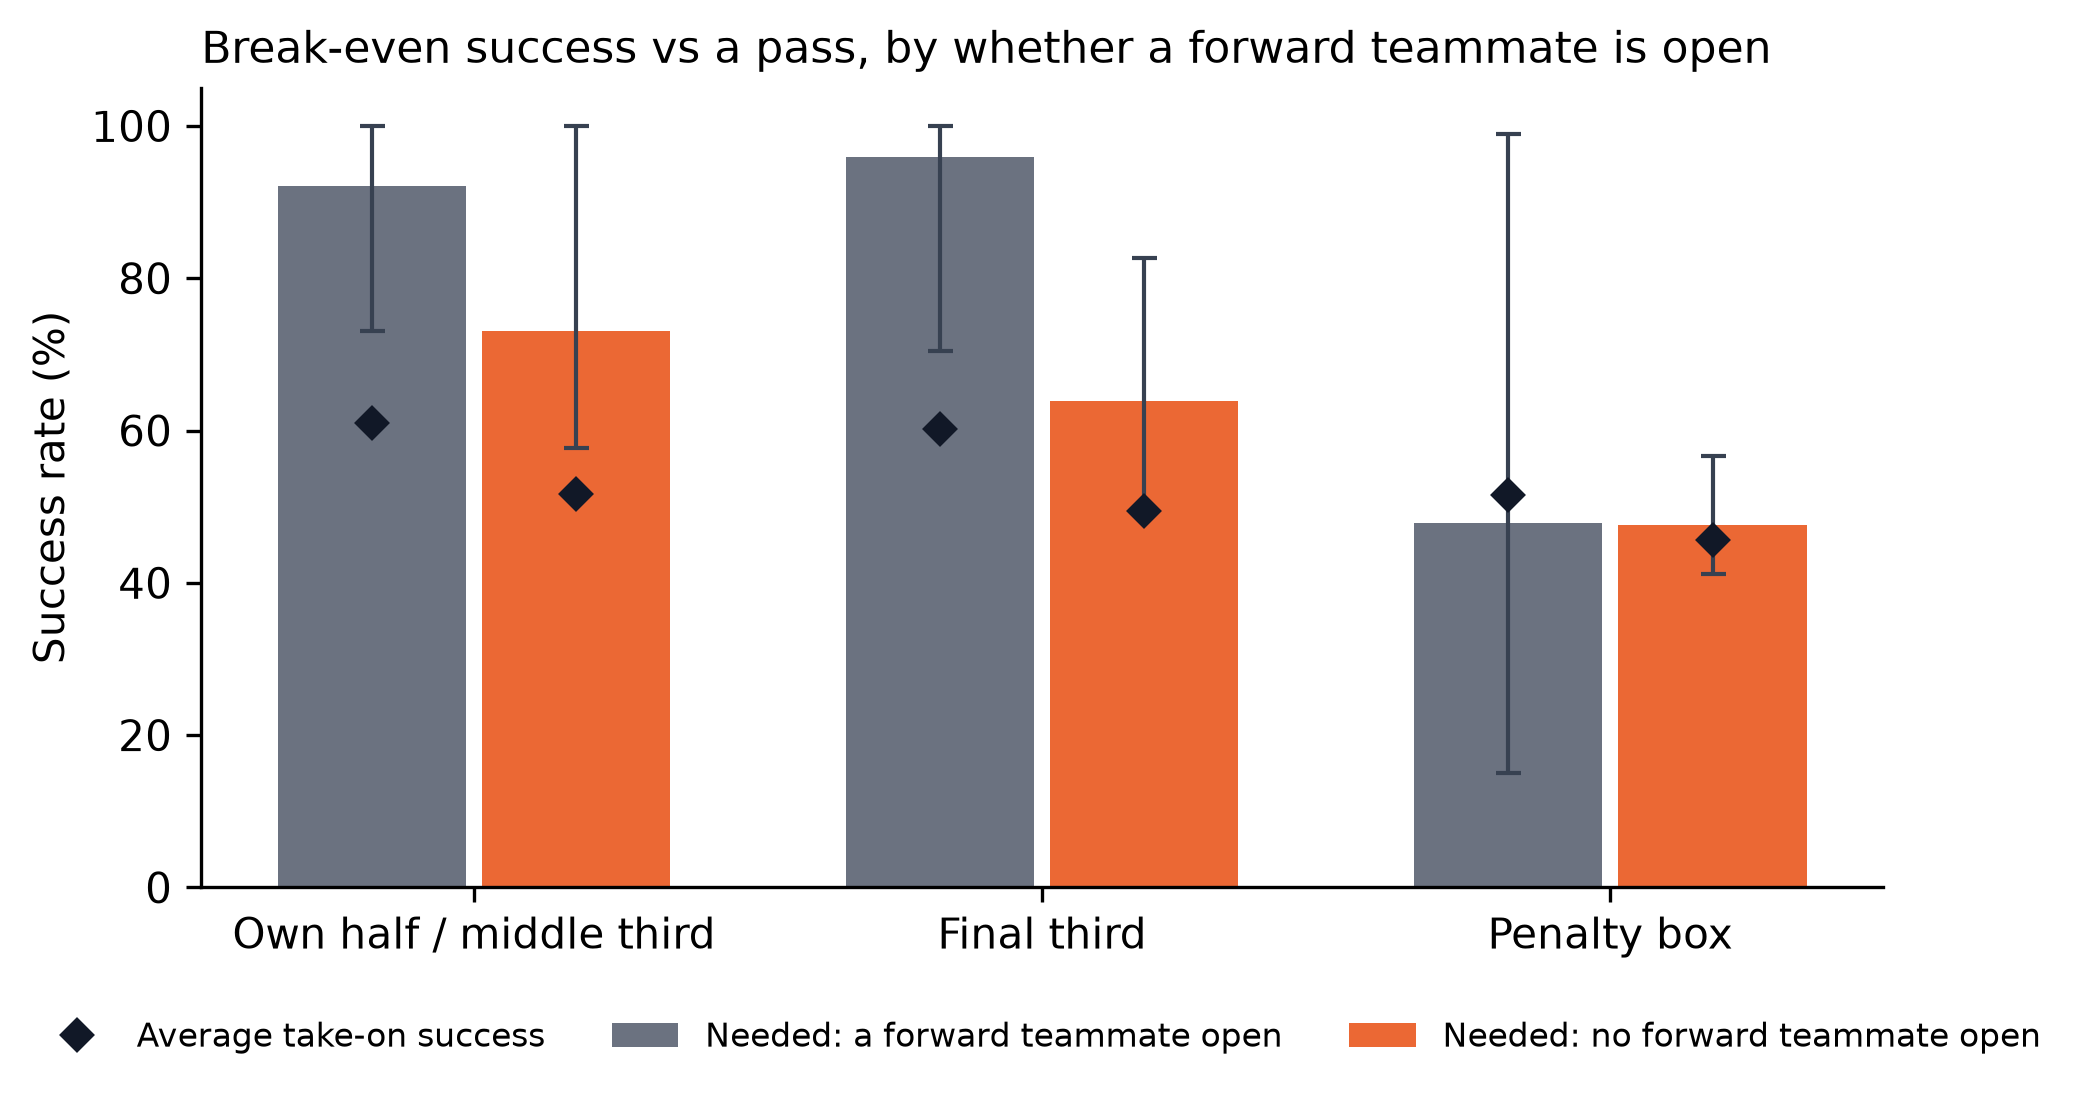

In [9]:
P.fig_360_breakeven(R);

### A.4 Study 5: a second data provider

All of Studies 1–4 use StatsBomb’s definitions. Study 5 repeats the analysis on the public Wyscout release \[@pappalardo2019data\]: every match of the five major European leagues in 2017/18, plus the 2018 World Cup and Euro 2016 (1,941 matches, 3.25 million events). Wyscout is coded by a different company with different definitions, two seasons later, so agreement here is not an artefact of one provider’s conventions.

**Harmonisation.** A Wyscout take-on is a ground attacking duel tagged “take on left” or “take on right”; it is completed if tagged “won”. Duels tagged “neutral” (13% of attempts) count as not completed, and a sensitivity check drops them. Coordinates are rescaled from percentages to StatsBomb’s $120\times80$ grid. Wyscout has no possession identifiers and no expected goals, so we rebuild possessions as maximal runs of one team’s on-ball events (defending duels and fouls do not end a possession), mark a possession as a counter-attack if any of its events carries Wyscout’s counter-attack tag, and fit a logistic shot model (distance, angle, header, direct free kick; penalties fixed at 0.76) on the 42,499 league shots (AUC 0.775). Every duel appears twice in Wyscout, once for each player, so each take-on is paired with the defender’s duel within 1.5 seconds; 96% are paired. The parser is `wyscout.py`.

**Replication.** Wyscout records 52,727 take-ons, completed 60.1% of the time. The context effects have the same shape (69% in the defensive third, 44% in the box; 69% on counter-attacks against 60% in regular play), the cross-validated AUC is 0.61, and a completed take-on is followed by 0.028 xG against 0.003 after a failure. Among the 558 player-seasons with at least 900 minutes and 30 attempts, the skill spread is $\hat\tau=6.4$ points (5.7 when neutral duels are dropped), close to StatsBomb’s 5.8, so a rating needs 137–155 attempts for a reliability of 0.7 instead of 172. The half-season test repeats exactly (872 players, 17,753 second-half take-ons): the raw rate is worse than the league average (log loss 0.686 against 0.677) and the shrunk rating is best (0.657 against 0.660 for the context model; 95% interval of the gain 0.0015–0.0040).

**Where the providers disagree.** The dribble-or-pass map agrees in the centre and disagrees on the wings. The central box is the clearest take-on area for both (break-even 31% against an average of 50% in Wyscout), and the central final third pays for the average dribbler in both (46% against 61%). On the wings of the final third and the box, Wyscout’s average take-on is at break-even (53% needed, 55% achieved; 43% and 43%), where StatsBomb’s falls 33–42 points short. Completed wide take-ons are followed by more shot value in Wyscout than in StatsBomb (4.1 against 2.4 net xG per 100 in the box wings), which points to differences in what each provider counts as a wide take-on and in how its possession continues. The wing verdict should therefore be treated as provider-dependent and not used on its own.

**The same matches, coded twice.** 61 of the 64 matches of the 2018 World Cup could be paired between the two releases, and 290 players linked by name. On the same matches, StatsBomb records 1,299 take-ons by these players and Wyscout 909, at almost the same success rate (62.1% and 61.8%). Agreement on a player’s attempts in a match is only moderate: Lin’s concordance correlation \[@lin1989\] is 0.51, ICC(2,1) \[@shrout1979\] 0.51, and the Bland–Altman 95% limits \[@blandaltman1986\] for the difference (Wyscout minus StatsBomb) run from $-4.2$ to $+2.9$ attempts per player-match around a mean of $-0.6$. Over the whole tournament the concordance of a player’s total attempts rises to 0.75, and for the 14 players with at least 10 attempts in both sources their success rates correlate at 0.79. Provider definitions therefore add a measurement error of their own, largest for single matches, on top of the binomial noise of @sec-reliability.

**The same players, two seasons and two providers apart.** 130 players rated in the StatsBomb 2015/16 benchmark (@tbl-bench) could be matched by name to a Wyscout 2017/18 rating. Their success above expectation correlates at $r=0.23$ (95% interval 0.05–0.39). Both ratings are noisy (mean reliability 0.47 in each), and Spearman’s correction for attenuation \[@spearman1904\], $$\hat\rho_{\text{true}} = \frac{r}{\sqrt{\bar\rho_{\text{SB}}\,\bar\rho_{\text{WY}}}},$$ {#eq-disatt} gives an estimated correlation of 0.48 (0.11–0.84) between the underlying skills. Take-on skill is therefore stable to a moderate degree across two seasons and a change of provider, but far from fixed. Out of sample, the 2015/16 StatsBomb rating adds nothing measurable to Wyscout’s own context model when predicting the same players’ 7,346 take-ons in 2017/18 (log loss 0.6662 with and without it; 95% interval of the gain $-0.0027$ to $0.0024$), and their raw 2015/16 completion rate again predicts worse than a constant (0.690 against 0.677).

### A.5 Study 6: attacker or defender? A crossed random-effects model

The empirical Bayes rating of @eq-oe credits the attacker with everything the context model does not explain, including the quality of the defender he faced. With the defender of each take-on identified (StatsBomb: the player recorded as dribbled past, or the tackler of a failed take-on, 94% of benchmark take-ons; Wyscout: the paired defending duel, 96%), we fit the crossed random-effects model $$\operatorname{logit}\Pr(y_i=1) = \mathbf{x}_i^\top\boldsymbol\beta + a_{j(i)} + d_{k(i)},\qquad a_j\sim\mathcal N(0,\sigma_a^2),\quad d_k\sim\mathcal N(0,\sigma_d^2),$$ {#eq-glmm} where $\mathbf{x}_i$ is the context of @eq-glm, $a_j$ the attacker’s and $d_k$ the defender’s effect. It is a Rasch-type paired-comparison model \[@rasch1960\] with covariates, fitted with `lme4` \[@bates2015\]. On the probability scale a logit standard deviation $\sigma$ corresponds to about $\sigma\,\bar p(1-\bar p)$, which makes $\sigma_a$ directly comparable with $\hat\tau$. We compare it with an attacker-only model and with a model in which the defending team replaces the individual defender, and we fit it separately to StatsBomb 2015/16 (49,369 take-ons, 1,875 attackers, 1,951 defenders) and Wyscout 2017/18 (48,356; 2,158; 2,300).

**Defenders differ more than attackers.** @fig-attdef shows the result. The attacker standard deviation is 5.7 points in StatsBomb and 6.0 in Wyscout, matching the two-stage estimates, so the reliability arithmetic of @sec-reliability stands (178 and 157 attempts for reliability 0.7). The individual defender varies more: 9.6 points in StatsBomb and 7.2 in Wyscout. Adding defenders improves the model decisively (likelihood-ratio $\chi^2_1=459$ and 184; AIC falls by 457 and 182), whereas the defending team adds little (1.7 and 2.1 points). Of the variance that the two players in a duel contribute, the attacker accounts for 26% (StatsBomb) to 41% (Wyscout). The StatsBomb figure may overstate the defender’s share, because the recorded defender of a completed take-on (the player dribbled past) and of a failed one (the tackler) are identified differently; Wyscout pairs the duel the same way whatever the outcome and still finds defenders more variable than attackers. On the latent scale both shares are small next to the logistic residual \[@nakagawa2013\]: a single duel is mostly decided by things neither player’s average explains.

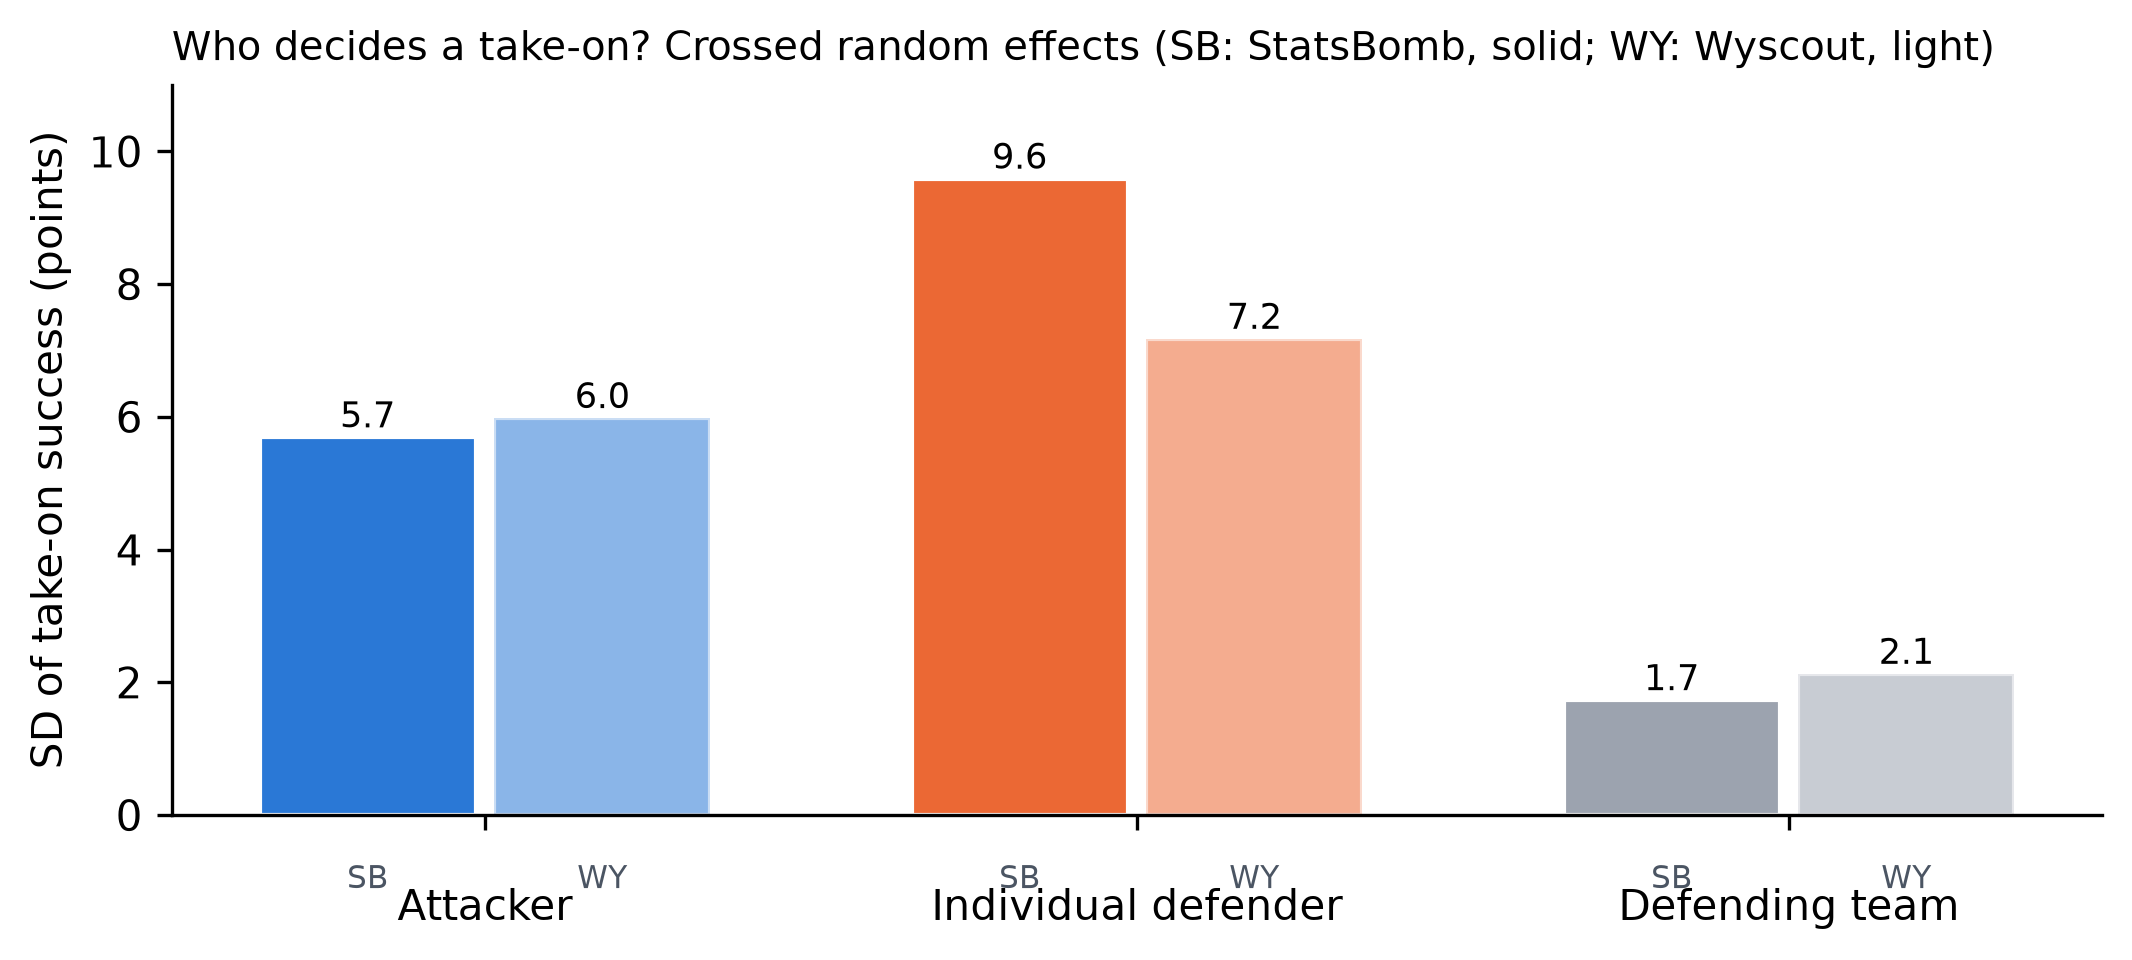

In [10]:
P.fig_attack_defence(R);

**Attacker ratings survive.** For attackers with at least 30 take-ons, the attacker effects with and without defenders in the model correlate at 0.99 (StatsBomb) and 0.996 (Wyscout): over a season, attackers face a broad enough mix of defenders that the defender effects average out. The mixed-model attacker effects also agree with the two-stage empirical Bayes ratings of Study 1 (correlation 0.96 over the 604 rated players), and the player ranked first by the two-stage rating is also first in the mixed model. The simpler two-stage method used for the released ratings is therefore a good approximation. The new information is on the other side of the ball: one-against-one defending is a larger and equally measurable individual difference, which event-data ratings of defenders could exploit.

### A.6 Bayesian dribble-or-pass decisions for individual players

The break-even analysis of @sec-decision gives a threshold per area; a player has his own success rate, known only with uncertainty. For player $j$ in area $c$, with posterior rating $\theta_j\sim\mathcal N(\widehat{\mathrm{OE}}_j, s_j^2)$ from @eq-oe, area success $\bar s_c$ and a break-even rate $p^*_c$ with standard error $e_c$ (from its match-resampled interval), the posterior probability that attempting the take-on beats the pass is $$\pi_{jc}=\Pr\!\left(\bar s_c+\theta_j>p^*_c\right)=\Phi\!\left(\frac{\bar s_c+\widehat{\mathrm{OE}}_j-p^*_c}{\sqrt{s_j^2+e_c^2}}\right),$$ {#eq-bayesdec} and the expected net gain of attempting rather than passing, per 100 attempts, is $(\bar s_c+\widehat{\mathrm{OE}}_j)(V_s-V_f)+V_f-V_p$ in the notation of @eq-breakeven. We call a decision confident when $\pi_{jc}>0.8$ (take on) or $\pi_{jc}<0.2$ (pass). A player’s *decision score* is the attempt-weighted average of his expected net gain over the areas where he actually took players on.

**Results.** Over the 604 benchmark players and 12 areas, 8% of player–area cells are confident take-on calls, 69% confident pass calls and 22% uncertain. The central box is a confident take-on call for every player; the central channel of the middle and final thirds and the wings of a team’s own third are uncertain for most players, which is exactly where an individual player’s skill decides; everywhere else the pass is the confident call. Decision scores correlate with skill ($r=0.58$), but where a player chooses to dribble matters more: with every player’s skill set to average and his own mix of areas kept, the scores retain two-thirds of their variance (correlation 0.83 with the full score). Messi in 2015/16 has by far the highest score, $+0.47$ xG per 100 take-ons above passing in the same areas, because he is both the most skilled dribbler and attempts a third of his take-ons where a take-on is the confident call for him (@fig-decqual). Because the pass comparator is conservative (Appendix A.3; Appendix A.4), the absolute scores are biased against take-ons and only their ranking should be used.

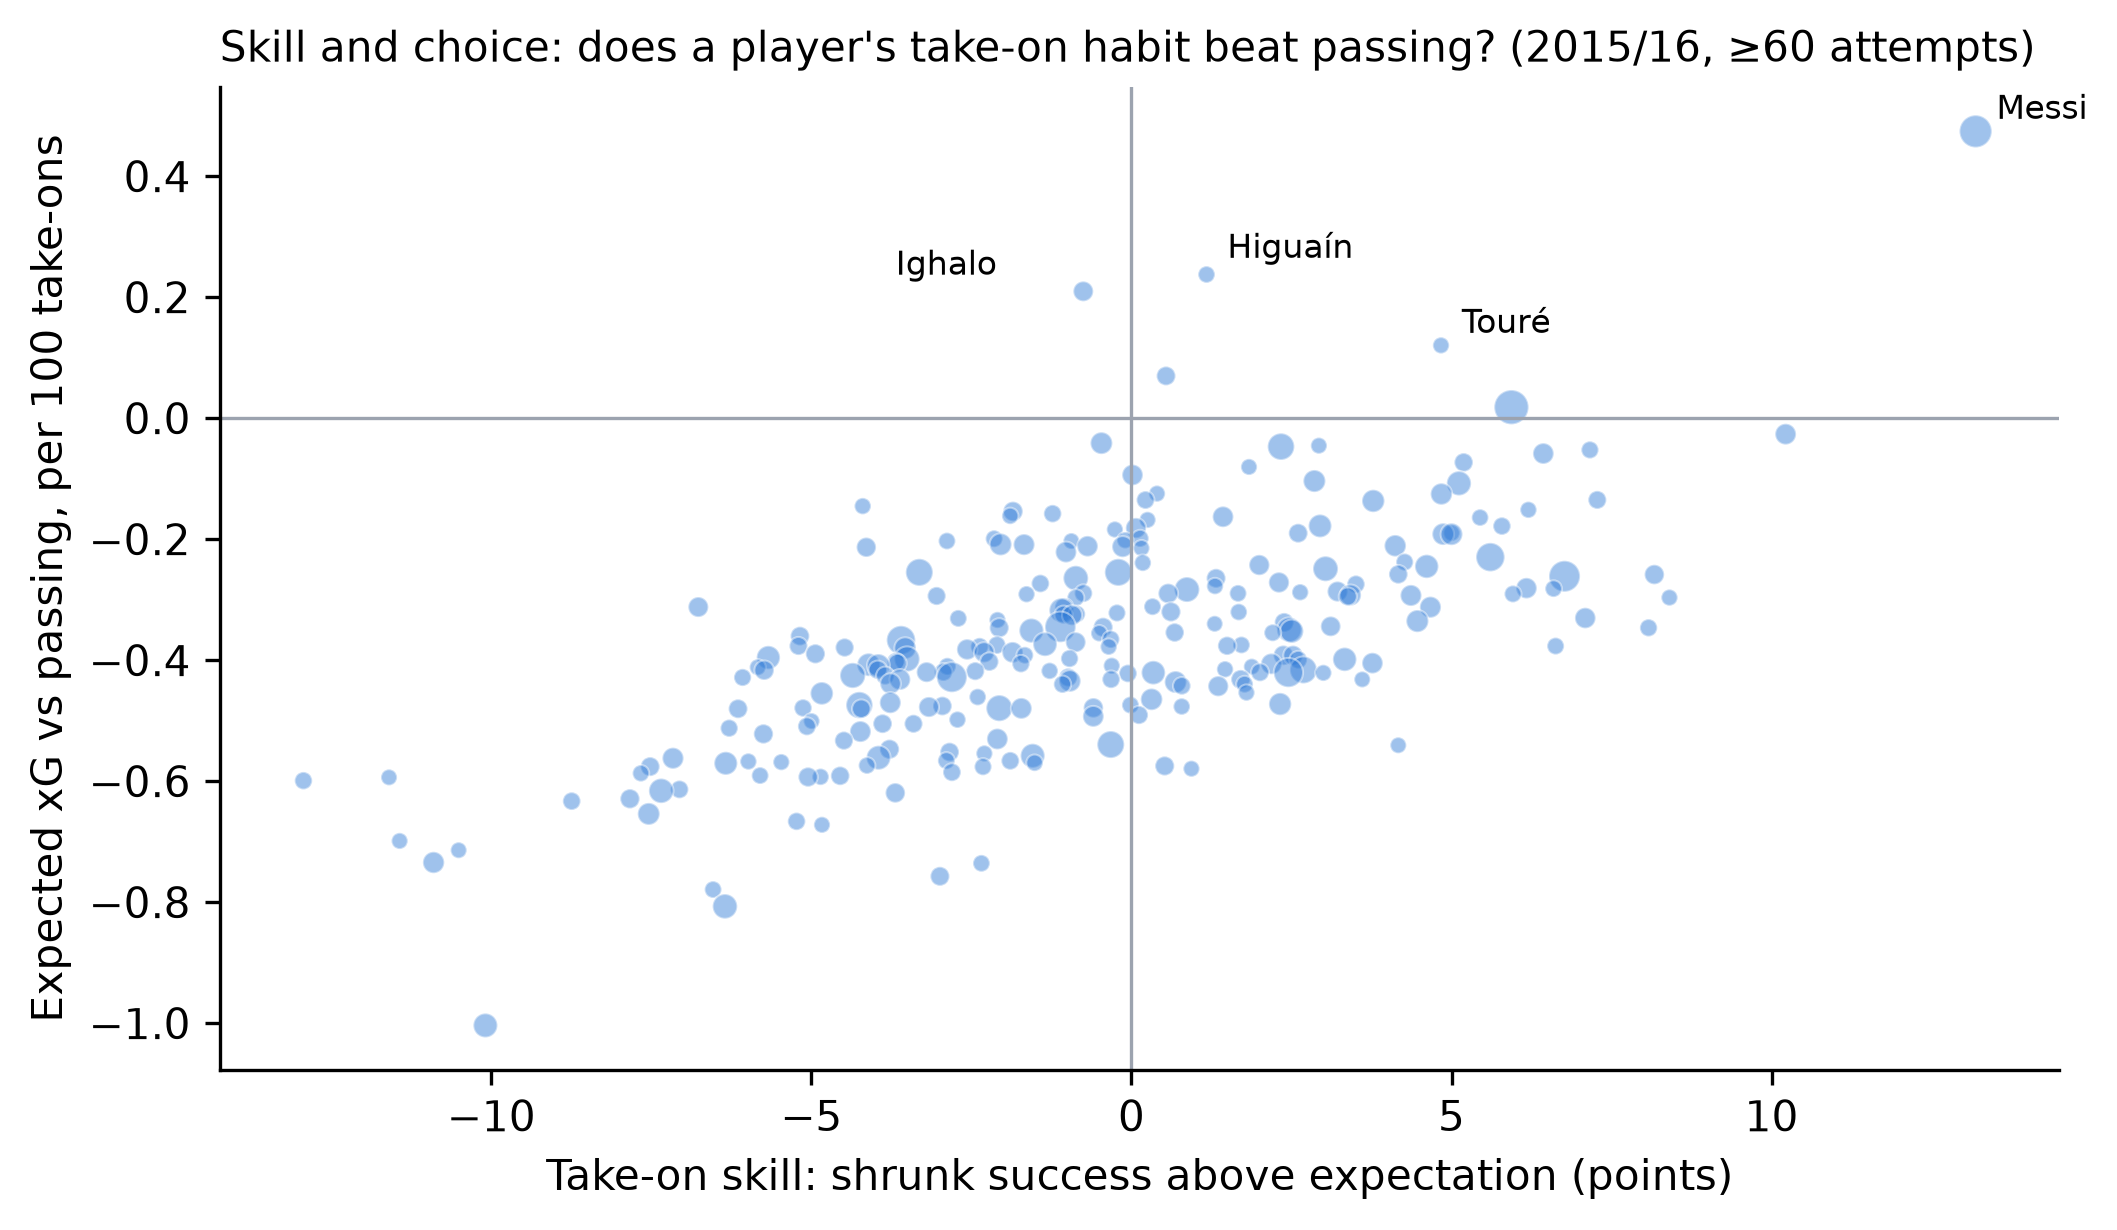

In [11]:
P.fig_decision_quality(R);

## Appendix B: Sensitivity and career

| Specification | Pool | Messi rank | Messi (pts) | Next (pts) |
|:-------------------------------------------|----:|-------:|--------:|-------:|
| Main model (@eq-glm) | 613 | 1 | $+13.2$ | $+10.2$ |
| No late-game term | 613 | 1 | $+13.2$ | $+10.2$ |
| No zone terms | 613 | 1 | $+15.3$ | $+14.3$ |
| Final third $\times$ game state interaction | 613 | 1 | $+13.2$ | $+10.2$ |
| At least 50 attempts | 333 | 1 | $+13.1$ | $+10.0$ |
| At least 100 attempts | 74 | 1 | $+13.1$ | $+10.1$ |
| La Liga players only | 169 | 1 | $+13.7$ | $+7.5$ |
| Out-of-fold context model (5 folds by match) | 604 | 1 | $+13.1$ | $+10.2$ |

The 2015/16 ranking is stable across seven alternative specifications (@tbl-sens; the pool is 613 rather than 604 because the sensitivity script applies the 30-attempt rule before the minutes filter). Dropping the zone terms narrows the gap to the second player the most, which is the context effect of @sec-context at work.

**One season is not a career.** Across 18 seasons with at least 50 attempts, Messi was above expectation in 17, and the match-clustered lower bound was above zero in 12 (@fig-career). His median season was $+6.9$ points, which would rank about eleventh of 604 in 2015/16. The one season with complete leagues happens to be his best adjusted season, so “first” describes a peak, and a typical season is top 2%. This is the reliability problem of @sec-reliability in a single career: even for a player with an unusually large sample, single-season ratings vary by several points.

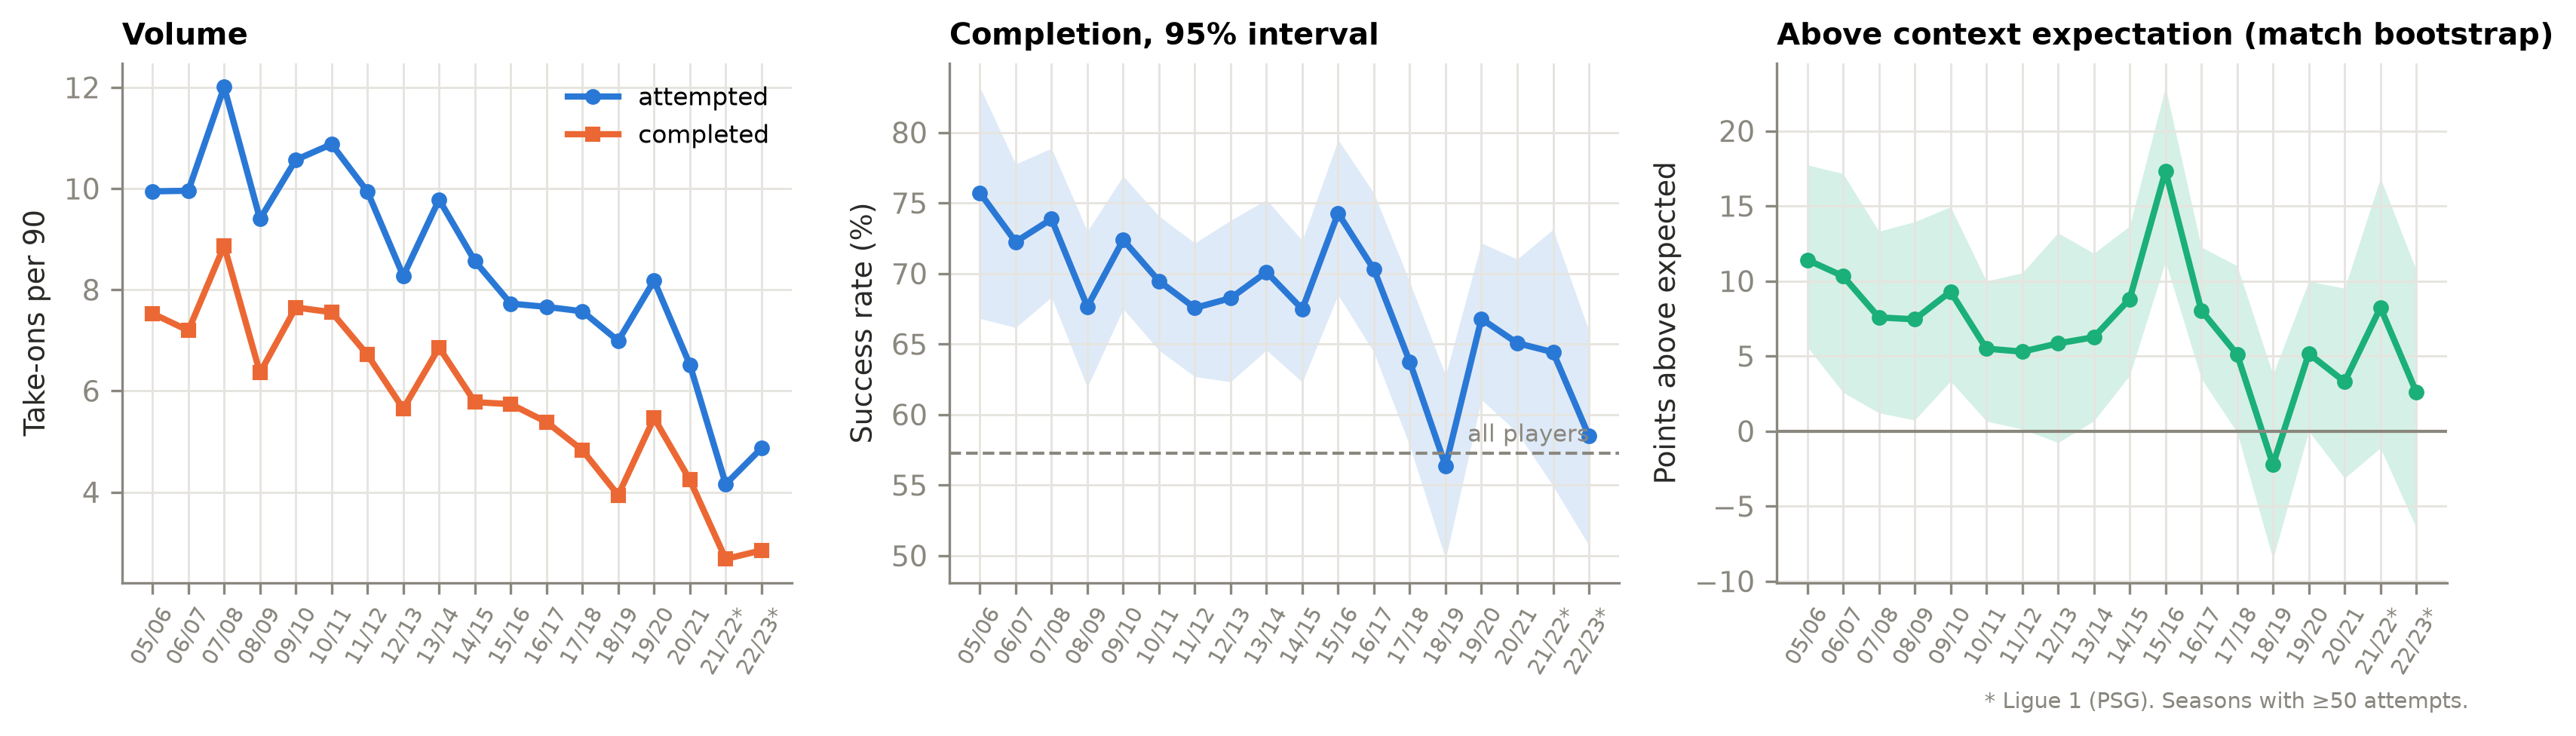

In [12]:
P.fig_career(R);